# Facial Emotion Recognition with CNN — FER2013
## Starter Notebook

</div>

---
## 📖 About the Dataset

**Source:** [FER2013 on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

FER2013 (*Facial Expression Recognition 2013*) was introduced in a Kaggle competition in 2013 as part of the ICML workshop *"Challenges in Representation Learning"*. The faces were collected automatically from Google image search, so they are **real-world faces**: different ages, poses, lighting, glasses, hands covering the face, etc.

| Property | Value |
|---|---|
| Total images | ~35,900 |
| Image size | **48 × 48 pixels** |
| Color | **Grayscale** (1 channel) |
| Classes | **7 emotions** |
| Train / Test | ~28,700 / ~7,200 images |
| Format | `.jpg` files in one folder per class |

**The 7 classes:** `angry` 😠 · `disgust` 🤢 · `fear` 😨 · `happy` 😄 · `neutral` 😐 · `sad` 😢 · `surprise` 😲

**Folder structure:**
```
fer2013/
├── train/
│   ├── angry/     ├── disgust/   ├── fear/   ├── happy/
│   ├── neutral/   ├── sad/       └── surprise/
└── test/
    └── (same 7 folders)
```

### ⚠️ Things to know before you start
1. **The classes are imbalanced** — `happy` has ~7,000 training images while `disgust` has only ~400. A model can get "good" accuracy just by ignoring the rare classes, so look at **per-class** results, not only overall accuracy.
2. **The task is hard** — the images are small and blurry, and some emotions look alike (fear vs. surprise, sad vs. neutral). Human accuracy on this dataset is estimated at only **~65%**, so don't expect 95%!
3. **There is no validation set** — we will create one from the training set.
4. **Some labels are noisy** — a few images are mislabeled or are not faces at all.

<div dir="rtl">

---
## 📖 نبذة عن البيانات

**المصدر:** [FER2013 على Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

بيانات FER2013 (*التعرّف على تعابير الوجه 2013*) نُشرت في مسابقة على Kaggle عام 2013 ضمن ورشة ICML بعنوان *"تحديات تعلّم التمثيلات"*. جُمعت الوجوه تلقائياً من بحث صور Google، لذلك هي **وجوه من الواقع**: أعمار مختلفة، وضعيات مختلفة، إضاءة متفاوتة، نظارات، أيدٍ تغطي الوجه... إلخ.

| الخاصية | القيمة |
|---|---|
| عدد الصور الكلي | حوالي 35,900 |
| حجم الصورة | **48 × 48 بكسل** |
| الألوان | **رمادية (Grayscale)** — قناة واحدة |
| عدد الأصناف | **7 مشاعر** |
| تدريب / اختبار | حوالي 28,700 / 7,200 صورة |
| الصيغة | ملفات `.jpg` في مجلد لكل صنف |

**الأصناف السبعة:** `angry` غضب 😠 · `disgust` اشمئزاز 🤢 · `fear` خوف 😨 · `happy` سعادة 😄 · `neutral` محايد 😐 · `sad` حزن 😢 · `surprise` مفاجأة 😲

### ⚠️ أمور مهمة قبل البدء
1. **الأصناف غير متوازنة** — صنف `happy` فيه حوالي 7,000 صورة تدريب بينما `disgust` فيه حوالي 400 فقط. النموذج قد يحصل على دقة "جيدة" وهو يتجاهل الأصناف النادرة، لذلك انظر إلى النتائج **لكل صنف** وليس الدقة الكلية فقط.
2. **المهمة صعبة** — الصور صغيرة وغير واضحة، وبعض المشاعر متشابهة (الخوف والمفاجأة، الحزن والمحايد). دقة الإنسان على هذه البيانات تُقدّر بحوالي **65%** فقط، فلا تتوقع 95%!
3. **لا توجد بيانات تحقق (validation)** — سننشئها من بيانات التدريب.
4. **بعض التسميات فيها أخطاء** — بعض الصور مصنّفة خطأ أو ليست وجوهاً أصلاً.

</div>

---
## 1. Setup
> In Colab, enable the GPU: **Runtime → Change runtime type → T4 GPU**

<div dir="rtl">

## 1. الإعداد
> في Colab فعّل الـ GPU من: **Runtime → Change runtime type → T4 GPU**

</div>

In [1]:
# Install kagglehub (used to download datasets from Kaggle)
# تثبيت مكتبة kagglehub لتحميل البيانات من Kaggle
!pip install -q kagglehub

In [2]:
import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split

# ---- Reproducibility: same random results every run ----
# ---- تثبيت العشوائية: نفس النتائج في كل تشغيل ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU if available, otherwise the CPU
# استخدم الـ GPU إن وُجد، وإلا الـ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Download the Data
We use `kagglehub` to download the dataset directly from Kaggle.
> If you get an authentication error: in Colab open 🔑 **Secrets** and add `KAGGLE_USERNAME` and `KAGGLE_KEY` (from Kaggle → Settings → API → Create New Token).

<div dir="rtl">

## 2. تحميل البيانات
نستخدم `kagglehub` لتحميل البيانات مباشرة من Kaggle.
> إذا ظهر خطأ في الصلاحيات: من Colab افتح 🔑 **Secrets** وأضف `KAGGLE_USERNAME` و `KAGGLE_KEY` (من Kaggle ← Settings ← API ← Create New Token).

</div>

In [3]:
import kagglehub

# Download the dataset (it is cached, so running again is instant)
# تحميل البيانات (تُحفظ مؤقتاً، فإعادة التشغيل تكون فورية)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

# Locate the train/ and test/ folders
# تحديد مسار مجلدي التدريب والاختبار
TRAIN_DIR = os.path.join(path, "train")
TEST_DIR  = os.path.join(path, "test")
print("Train folder:", TRAIN_DIR, "| exists:", os.path.isdir(TRAIN_DIR))
print("Test folder: ", TEST_DIR,  "| exists:", os.path.isdir(TEST_DIR))
print("Class folders:", sorted(os.listdir(TRAIN_DIR)))

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013
Train folder: /kaggle/input/fer2013/train | exists: True
Test folder:  /kaggle/input/fer2013/test | exists: True
Class folders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Explore the Data

<div dir="rtl">

## 3. استكشاف البيانات

</div>

In [4]:
# ImageFolder reads a "one folder per class" structure:
# the folder name becomes the class name, and each image gets that label.
# ImageFolder يقرأ البيانات المنظّمة بمجلد لكل صنف:
# اسم المجلد يصبح اسم الصنف، وكل صورة تأخذ تسمية مجلدها.
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test  = datasets.ImageFolder(TEST_DIR)

CLASS_NAMES = raw_train.classes          # ['angry', 'disgust', 'fear', ...]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", dict(enumerate(CLASS_NAMES)))
print("Train images:", len(raw_train))
print("Test images: ", len(raw_test))

# Check the size and mode of one image (L = grayscale)
# فحص حجم ونوع صورة واحدة (L تعني رمادية)
img, label = raw_train[0]
print("Image size:", img.size, "| mode:", img.mode, "| label:", CLASS_NAMES[label])

Classes: {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}
Train images: 28709
Test images:  7178
Image size: (48, 48) | mode: RGB | label: angry


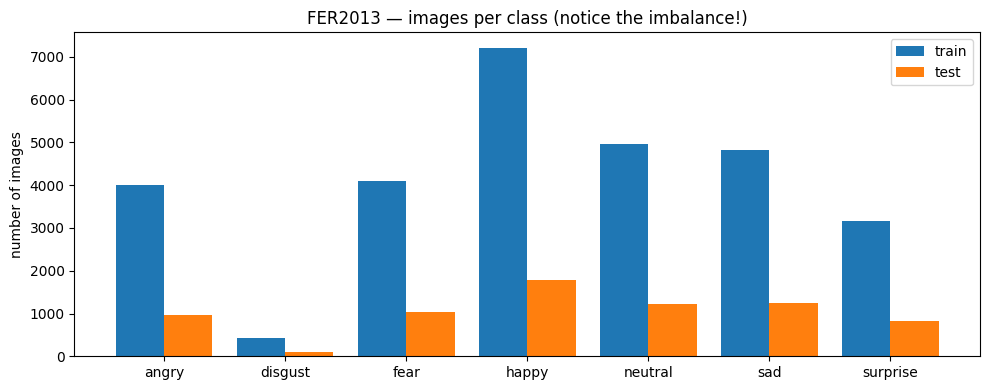

angry      train:  3995   test:   958
disgust    train:   436   test:   111
fear       train:  4097   test:  1024
happy      train:  7215   test:  1774
neutral    train:  4965   test:  1233
sad        train:  4830   test:  1247
surprise   train:  3171   test:   831


In [5]:
# ---- Class distribution: how many images per emotion? ----
# ---- توزيع الأصناف: كم صورة لكل شعور؟ ----
train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)

x = np.arange(NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [train_counts[i] for i in range(NUM_CLASSES)], width=0.4, label="train")
plt.bar(x + 0.2, [test_counts[i]  for i in range(NUM_CLASSES)], width=0.4, label="test")
plt.xticks(x, CLASS_NAMES)
plt.ylabel("number of images")
plt.title("FER2013 — images per class (notice the imbalance!)")
plt.legend()
plt.tight_layout()
plt.show()

for i, name in enumerate(CLASS_NAMES):
    print(f"{name:<10} train: {train_counts[i]:>5}   test: {test_counts[i]:>5}")

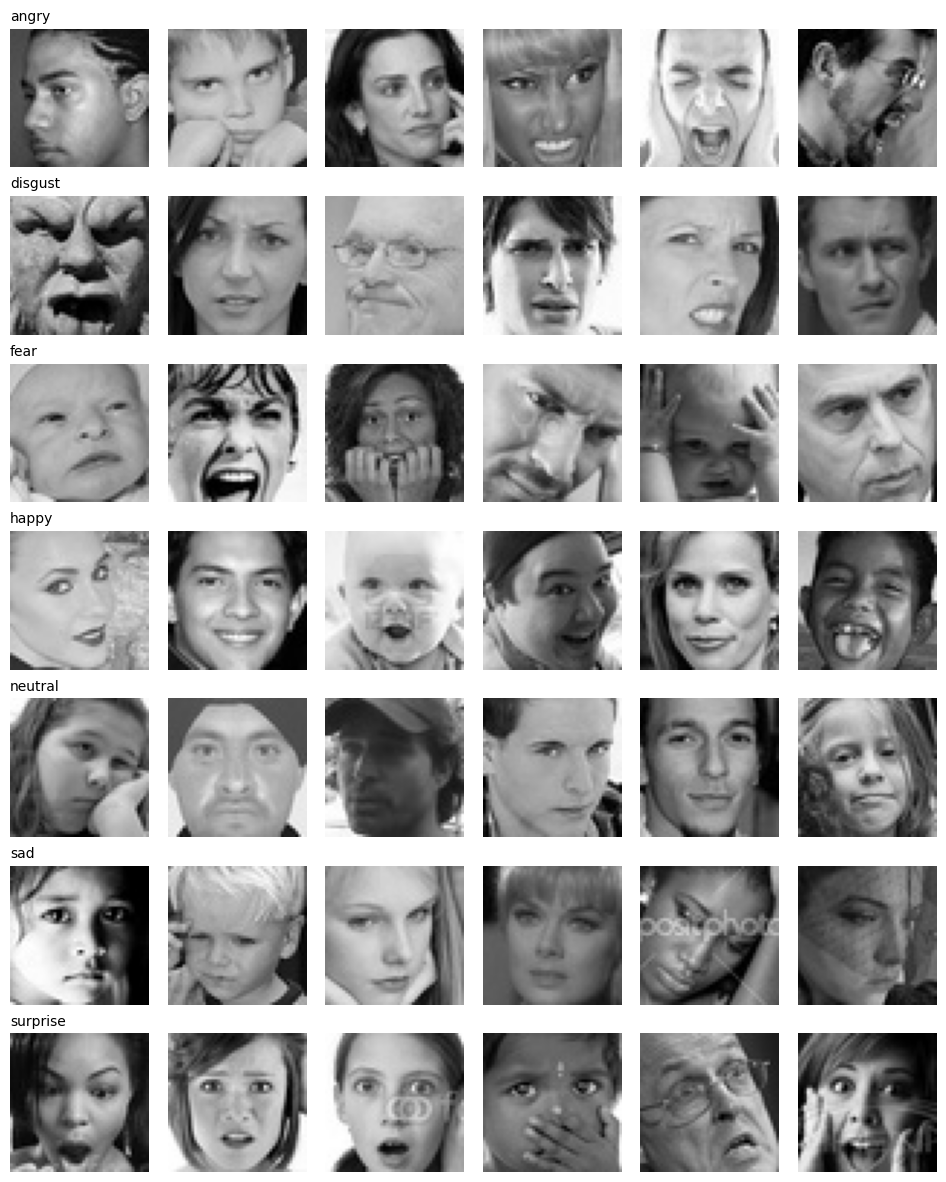

In [6]:
# ---- Show random examples from each class ----
# ---- عرض أمثلة عشوائية من كل صنف ----
N_PER_CLASS = 6
train_targets = np.array(raw_train.targets)

fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, NUM_CLASSES * 1.7))
for c in range(NUM_CLASSES):
    # pick random image indices that belong to class c
    # اختيار صور عشوائية تنتمي للصنف c
    idxs = np.random.choice(np.where(train_targets == c)[0], N_PER_CLASS, replace=False)
    for j, idx in enumerate(idxs):
        img, _ = raw_train[idx]
        axes[c, j].imshow(img, cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [7]:

# Split Training and Validation Data
# تقسيم بيانات التدريب إلى تدريب وتحقق

# Get image indices and labels
indices = np.arange(len(raw_train))
targets = np.array(raw_train.targets)

# Split training data: 80% Train, 20% Validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=targets
)

# Create training and validation subsets
train_data = Subset(raw_train, train_indices)
val_data = Subset(raw_train, val_indices)

# Display dataset sizes
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(raw_test))


Training images: 22967
Validation images: 5742
Testing images: 7178


In [8]:

#  Data Augmentation & DataLoaders
# تجهيز الصور للتدريب والتحقق والاختبار

# Training transformations
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Validation and Testing transformations
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# Load datasets with transformations
train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)

val_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

# Use the same training and validation indices
train_data = Subset(train_dataset, train_indices)
val_data = Subset(val_dataset, val_indices)

# Create DataLoaders
BATCH_SIZE = 64

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_dataset))


Training images: 22967
Validation images: 5742
Testing images: 7178


In [9]:

# Check image shape and labels
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Number of classes:", NUM_CLASSES)


Images shape: torch.Size([64, 1, 48, 48])
Labels shape: torch.Size([64])
Number of classes: 7


## 4. Build and Train a CNN Model

We build a CNN model from scratch, train it on the FER2013 dataset, and evaluate its performance on the test data.

**This section includes:**
- Build the CNN architecture for the seven emotion classes.
- Check the model output dimensions before training.
- Train the model and save checkpoints so training can resume.
- Review the training and validation loss and accuracy.
- Load the best saved model and evaluate it on the test set.
- Review the confusion matrix, classification report, and final evaluation metrics.

<div dir="rtl">

## 4. بناء وتدريب نموذج CNN

نبني نموذج CNN من الصفر، وندرّبه على بيانات FER2013، ثم نقيّم أداءه باستخدام بيانات الاختبار.

**تشمل هذه المرحلة:**
- بناء هيكل نموذج CNN لتصنيف فئات المشاعر السبعة.
- التحقق من أبعاد مخرجات النموذج قبل التدريب.
- تدريب النموذج وحفظ نقاط الاستكمال لمتابعة التدريب لاحقًا.
- مراجعة الخسارة والدقة لبيانات التدريب والتحقق.
- تحميل أفضل نموذج محفوظ وتقييمه باستخدام بيانات الاختبار.
- مراجعة مصفوفة الالتباس وتقرير التصنيف ومقاييس التقييم النهائية.

</div>

In [10]:

# 6. Build CNN Model
# بناء نموذج CNN من الصفر

import torch.nn as nn

class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(EmotionCNN, self).__init__()

        self.features = nn.Sequential(
            # First Convolution Block
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            # Second Convolution Block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            # Third Convolution Block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            # Fourth Convolution Block
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Initialize model
model = EmotionCNN(num_classes=NUM_CLASSES).to(device)

print(model)


EmotionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout2d(p=0.2, in

In [11]:

# Check CNN output shape
# التأكد من أبعاد مخرجات النموذج

model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(train_loader))
    sample_images = sample_images.to(device)

    outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Total parameters:",
      sum(p.numel() for p in model.parameters()))


Input shape: torch.Size([64, 1, 48, 48])
Output shape: torch.Size([64, 7])
Total parameters: 1174887


In [12]:

# 7. Train CNN Model
# تدريب نموذج CNN مع الحفظ التلقائي والاستكمال

import os
import copy
import torch
import torch.nn as nn
import torch.optim as optim

from tqdm.auto import tqdm
from google.colab import drive

# ----------------------------------
# 1. Connect Google Drive
# ----------------------------------

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/FER2013_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

BEST_PATH = os.path.join(
    SAVE_DIR, "best_cnn_fer2013.pth"
)

CHECKPOINT_PATH = os.path.join(
    SAVE_DIR, "cnn_training_checkpoint.pth"
)

print("Models will be saved in:", SAVE_DIR)

# ----------------------------------
# 2. Device Setup
# ----------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Training Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Training will use CPU.")

# ----------------------------------
# 3. Loss Function and Optimizer
# ----------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# ----------------------------------
# 4. Learning Rate Scheduler
# ----------------------------------

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# ----------------------------------
# 5. Training Settings
# ----------------------------------

EPOCHS = 30
PATIENCE = 5

start_epoch = 0
best_val_acc = 0.0
epochs_without_improvement = 0

best_model_weights = copy.deepcopy(
    model.state_dict()
)

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# ----------------------------------
# 6. Resume Training if Available
# ----------------------------------

if os.path.exists(CHECKPOINT_PATH):

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch = checkpoint["epoch"] + 1
    best_val_acc = checkpoint["best_val_acc"]

    epochs_without_improvement = checkpoint[
        "epochs_without_improvement"
    ]

    train_losses = checkpoint["train_losses"]
    val_losses = checkpoint["val_losses"]
    train_accuracies = checkpoint["train_accuracies"]
    val_accuracies = checkpoint["val_accuracies"]

    if os.path.exists(BEST_PATH):
        best_model_weights = torch.load(
            BEST_PATH,
            map_location=device,
            weights_only=True
        )

    print(
        f"Resuming training from Epoch {start_epoch + 1}"
    )

else:
    print("Starting CNN training from the beginning.")

# ----------------------------------
# 7. Training Loop
# ----------------------------------

for epoch in range(start_epoch, EPOCHS):

    # Training
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} - Training"
    )

    for images, labels in train_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        train_bar.set_postfix(
            loss=f"{running_loss/total:.4f}",
            acc=f"{100*correct/total:.2f}%"
        )

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # ----------------------------------
    # Validation
    # ----------------------------------

    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += (
                loss.item() * images.size(0)
            )

            predicted = outputs.argmax(dim=1)

            val_total += labels.size(0)
            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = running_val_loss / val_total
    val_acc = 100 * val_correct / val_total

    # ----------------------------------
    # Store Results
    # ----------------------------------

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Update Learning Rate
    scheduler.step(val_loss)

    # ----------------------------------
    # Save Best Model
    # ----------------------------------

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_weights,
            BEST_PATH
        )

        epochs_without_improvement = 0

        print("Best CNN model saved to Google Drive!")

    else:
        epochs_without_improvement += 1

    # ----------------------------------
    # Save Checkpoint Every Epoch
    # ----------------------------------

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "epochs_without_improvement":
            epochs_without_improvement,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accuracies": train_accuracies,
        "val_accuracies": val_accuracies
    }

    torch.save(
        checkpoint,
        CHECKPOINT_PATH
    )

    # ----------------------------------
    # Print Results
    # ----------------------------------

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Best Val Acc: {best_val_acc:.2f}%"
    )

    print("Checkpoint saved to Google Drive.")

    # ----------------------------------
    # Early Stopping
    # ----------------------------------

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# ----------------------------------
# 8. Load Best CNN Model
# ----------------------------------

if os.path.exists(BEST_PATH):

    model.load_state_dict(
        torch.load(
            BEST_PATH,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()

    print(
        f"\nBest Validation Accuracy: "
        f"{best_val_acc:.2f}%"
    )

    print("Best Model:", BEST_PATH)
    print("Checkpoint:", CHECKPOINT_PATH)

else:
    print("No saved best model was found.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models will be saved in: /content/drive/MyDrive/FER2013_Models
Training Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Resuming training from Epoch 31

Best Validation Accuracy: 61.22%
Best Model: /content/drive/MyDrive/FER2013_Models/best_cnn_fer2013.pth
Checkpoint: /content/drive/MyDrive/FER2013_Models/cnn_training_checkpoint.pth


In [13]:

for i in range(len(train_losses)):
    print(
        f"Epoch {i+1}/{EPOCHS} | "
        f"Train Loss: {train_losses[i]:.4f} | "
        f"Train Acc: {train_accuracies[i]:.2f}% | "
        f"Val Loss: {val_losses[i]:.4f} | "
        f"Val Acc: {val_accuracies[i]:.2f}%"
    )

print(f"\nBest Validation Accuracy: {best_val_acc:.2f}%")


Epoch 1/30 | Train Loss: 1.8003 | Train Acc: 25.48% | Val Loss: 1.6933 | Val Acc: 32.13%
Epoch 2/30 | Train Loss: 1.6116 | Train Acc: 35.83% | Val Loss: 1.4573 | Val Acc: 42.18%
Epoch 3/30 | Train Loss: 1.4981 | Train Acc: 41.02% | Val Loss: 1.3789 | Val Acc: 46.69%
Epoch 4/30 | Train Loss: 1.4459 | Train Acc: 43.61% | Val Loss: 1.3126 | Val Acc: 47.70%
Epoch 5/30 | Train Loss: 1.4053 | Train Acc: 45.51% | Val Loss: 1.2615 | Val Acc: 51.01%
Epoch 6/30 | Train Loss: 1.3752 | Train Acc: 46.77% | Val Loss: 1.2703 | Val Acc: 50.09%
Epoch 7/30 | Train Loss: 1.3514 | Train Acc: 47.67% | Val Loss: 1.2198 | Val Acc: 53.15%
Epoch 8/30 | Train Loss: 1.3290 | Train Acc: 48.86% | Val Loss: 1.1924 | Val Acc: 54.27%
Epoch 9/30 | Train Loss: 1.3117 | Train Acc: 49.35% | Val Loss: 1.1935 | Val Acc: 53.92%
Epoch 10/30 | Train Loss: 1.3002 | Train Acc: 50.41% | Val Loss: 1.1775 | Val Acc: 54.63%
Epoch 11/30 | Train Loss: 1.2783 | Train Acc: 50.59% | Val Loss: 1.1800 | Val Acc: 54.81%
Epoch 12/30 | Train

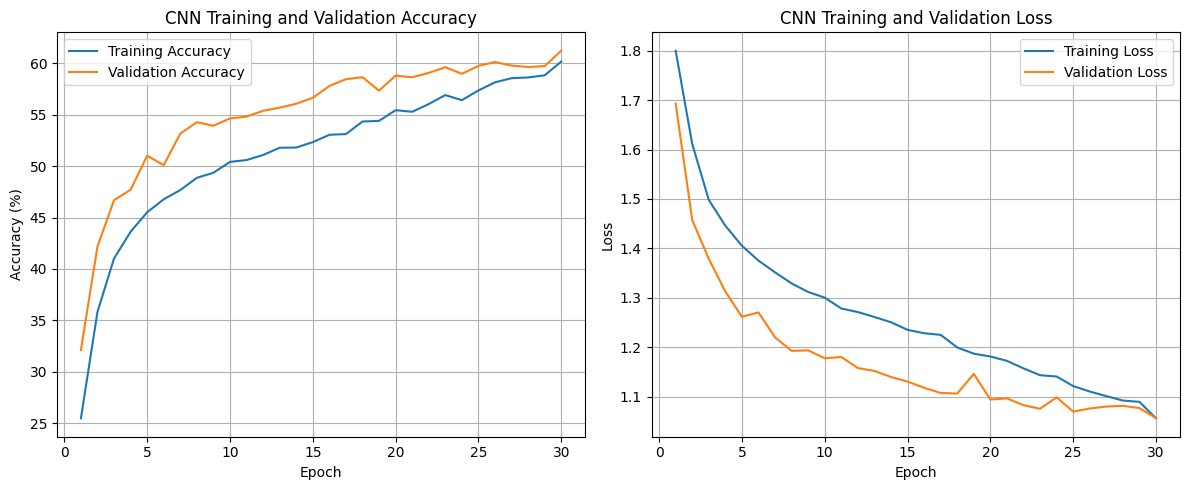

In [14]:

# 7.1 CNN Training Visualization

import matplotlib.pyplot as plt

epochs = range(1, len(train_accuracies) + 1)

plt.figure(figsize=(12, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)
plt.plot(epochs, train_accuracies, label="Training Accuracy")
plt.plot(epochs, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [15]:
# Restore Trained CNN Model

import os
import torch

CNN_PATH = "/content/drive/MyDrive/FER2013_Models/best_cnn_fer2013.pth"

if not os.path.exists(CNN_PATH):
    raise FileNotFoundError("CNN model not found in Google Drive")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# model must be your original EmotionCNN architecture
model.load_state_dict(
    torch.load(
        CNN_PATH,
        map_location=device,
        weights_only=True
    )
)

model = model.to(device)
model.eval()

print("CNN model restored successfully!")


CNN model restored successfully!


In [16]:

# 8. Evaluate CNN Model
# تقييم نموذج CNN على بيانات الاختبار

import torch
import torch.nn as nn

model.eval()

criterion = nn.CrossEntropyLoss()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_loss = test_loss / test_total
test_accuracy = 100 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")


Test Loss: 1.0357
Test Accuracy: 61.33%


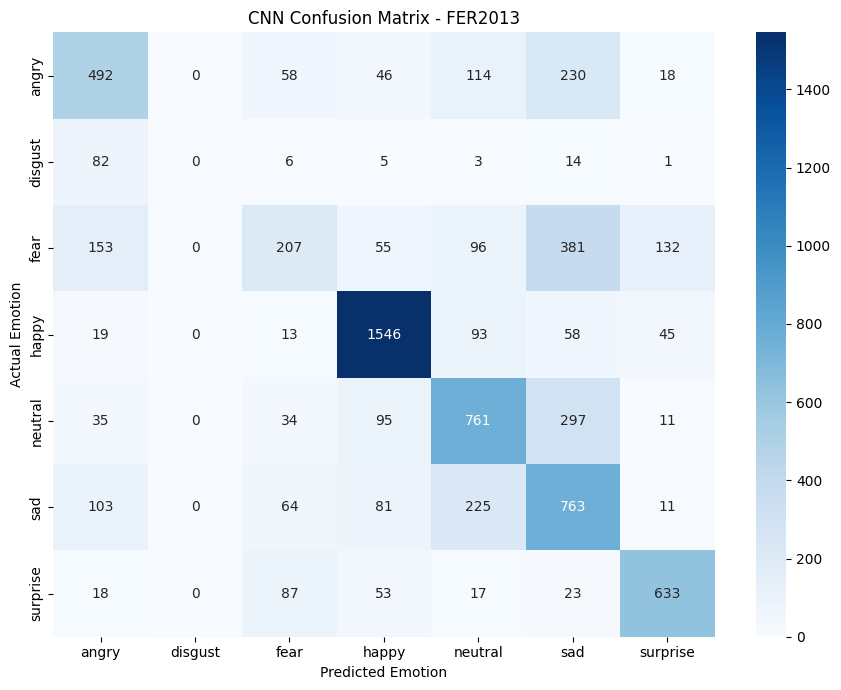

Classification Report:
              precision    recall  f1-score   support

       angry       0.55      0.51      0.53       958
     disgust       0.00      0.00      0.00       111
        fear       0.44      0.20      0.28      1024
       happy       0.82      0.87      0.85      1774
     neutral       0.58      0.62      0.60      1233
         sad       0.43      0.61      0.51      1247
    surprise       0.74      0.76      0.75       831

    accuracy                           0.61      7178
   macro avg       0.51      0.51      0.50      7178
weighted avg       0.60      0.61      0.60      7178



In [17]:

# 9. CNN Confusion Matrix

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predicted = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

class_names = test_loader.dataset.classes

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("CNN Confusion Matrix - FER2013")
plt.tight_layout()
plt.show()

print("Classification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)


In [18]:
# 9.1 CNN Final Evaluation Metrics

import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Restore CNN weights
cnn_model = EmotionCNN(
    num_classes=NUM_CLASSES
).to(device)

cnn_model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/FER2013_Models/best_cnn_fer2013.pth",
        map_location=device,
        weights_only=True
    )
)

cnn_model.eval()

cnn_true = []
cnn_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        cnn_true.extend(labels.numpy())
        cnn_pred.extend(predictions.cpu().numpy())

cnn_accuracy = accuracy_score(cnn_true, cnn_pred)
cnn_precision = precision_score(
    cnn_true, cnn_pred,
    average="macro", zero_division=0
)
cnn_recall = recall_score(
    cnn_true, cnn_pred,
    average="macro", zero_division=0
)
cnn_f1 = f1_score(
    cnn_true, cnn_pred,
    average="macro", zero_division=0
)

print("CNN Final Evaluation")
print(f"Accuracy: {cnn_accuracy*100:.2f}%")
print(f"Macro Precision: {cnn_precision*100:.2f}%")
print(f"Macro Recall: {cnn_recall*100:.2f}%")
print(f"Macro F1: {cnn_f1*100:.2f}%")

CNN Final Evaluation
Accuracy: 61.33%
Macro Precision: 50.94%
Macro Recall: 51.11%
Macro F1: 50.15%


## 5 . Transfer Learning Using ResNet18

We use a pretrained ResNet18 model and adapt it to classify the seven emotion classes in FER2013.

**This section includes:**
- Prepare image transformations and data loaders for ResNet18.
- Load pretrained ResNet18 weights.
- Freeze the pretrained feature layers and replace the final classification layer.
- Train the final layer while keeping the pretrained layers frozen.
- Review training history and evaluate the model using test metrics and a confusion matrix.
- Inspect the distribution of predictions and locate saved model checkpoints.

<div dir="rtl">

##5 . التعلّم بالنقل باستخدام ResNet18

نستخدم نموذج ResNet18 مدرّبًا مسبقًا ونعدّله لتصنيف فئات المشاعر السبعة في مجموعة بيانات FER2013.

**تشمل هذه المرحلة:**
- تجهيز تحويلات الصور وأدوات تحميل البيانات لنموذج ResNet18.
- تحميل أوزان نموذج ResNet18 المدرّب مسبقًا.
- تجميد طبقات استخراج الخصائص واستبدال طبقة التصنيف الأخيرة.
- تدريب الطبقة الأخيرة مع إبقاء الطبقات المدربة مسبقًا مجمّدة.
- مراجعة سجل التدريب وتقييم النموذج باستخدام مقاييس الاختبار ومصفوفة الالتباس.
- فحص توزيع التوقعات والبحث عن نقاط حفظ النموذج.

</div>

In [19]:
# ==========================================
# 10. Prepare Data for ResNet18
# تجهيز البيانات لنموذج ResNet18
# ==========================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Training transformations
resnet_train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

# Validation and testing transformations
resnet_eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

# Load datasets
resnet_train_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=resnet_train_transform
)

resnet_val_full = datasets.ImageFolder(
    TRAIN_DIR,
    transform=resnet_eval_transform
)

resnet_test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=resnet_eval_transform
)

# Reuse the existing training and validation split
resnet_train_dataset = Subset(
    resnet_train_full,
    train_indices
)

resnet_val_dataset = Subset(
    resnet_val_full,
    val_indices
)

# Set batch size according to the available device
RESNET_BATCH_SIZE = 32 if device.type == "cuda" else 16

# Create DataLoaders
resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify the data
images, labels = next(iter(resnet_train_loader))

print("Device:", device)
print("Training images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Classes:", resnet_train_full.classes)
print("Number of classes:", len(resnet_train_full.classes))
print("Training images:", len(resnet_train_dataset))
print("Validation images:", len(resnet_val_dataset))
print("Test images:", len(resnet_test_dataset))

Device: cuda
Training images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7
Training images: 22967
Validation images: 5742
Test images: 7178


In [20]:

# ==========================================
# 11. Load Pretrained ResNet18
# Transfer Learning - Feature Extraction
# ==========================================

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
resnet_model = resnet18(weights=weights)

# Freeze pretrained layers
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final layer for 7 emotion classes
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    NUM_CLASSES
)

# Move model to device
resnet_model = resnet_model.to(device)

# Verify model configuration
trainable_params = sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
)

print("ResNet18 loaded successfully!")
print("Training mode: Feature Extraction")
print("Output classes:", resnet_model.fc.out_features)
print("Trainable parameters:", trainable_params)
print("Device:", device)


ResNet18 loaded successfully!
Training mode: Feature Extraction
Output classes: 7
Trainable parameters: 3591
Device: cuda


In [21]:

# ==========================================
# 12. Configure ResNet18 Transfer Learning
# Feature Extraction - Train FC Layer Only
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim

# 1. Freeze pretrained backbone
for param in resnet_model.parameters():
    param.requires_grad = False

# 2. Unfreeze final classification layer
for param in resnet_model.fc.parameters():
    param.requires_grad = True

# 3. Keep frozen BatchNorm layers in evaluation mode
def set_resnet_feature_extraction_mode():
    resnet_model.eval()
    resnet_model.fc.train()

# 4. Loss function
resnet_criterion = nn.CrossEntropyLoss()

# 5. Optimizer - FC layer only
resnet_optimizer = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

# 6. Learning rate scheduler
resnet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    resnet_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# 7. Verify configuration
trainable_params = sum(
    p.numel() for p in resnet_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in resnet_model.parameters()
)

print("Training mode: Feature Extraction")
print("Loss function:", resnet_criterion)
print("Optimizer:", resnet_optimizer.__class__.__name__)
print("Initial learning rate:", resnet_optimizer.param_groups[0]["lr"])
print("Scheduler:", resnet_scheduler.__class__.__name__)
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)


Training mode: Feature Extraction
Loss function: CrossEntropyLoss()
Optimizer: Adam
Initial learning rate: 0.001
Scheduler: ReduceLROnPlateau
Trainable parameters: 3591
Total parameters: 11180103


In [22]:

# ==========================================
# 13. Train ResNet18 - Feature Extraction
# Google Drive Auto Save + Resume
# ==========================================

import os
import time
import copy
import torch
from google.colab import drive

# ------------------------------------------
# 1. Connect Google Drive
# ------------------------------------------

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/FER2013_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

# New paths - protect previous ResNet18 model
BEST_RESNET_PATH = os.path.join(
    SAVE_DIR, "best_resnet18_feature_extraction.pth"
)

RESNET_CHECKPOINT_PATH = os.path.join(
    SAVE_DIR, "resnet18_feature_extraction_checkpoint.pth"
)

print("Saving Feature Extraction models to:", SAVE_DIR)

# ------------------------------------------
# 2. Training Settings
# ------------------------------------------

RESNET_EPOCHS = 10

resnet_model = resnet_model.to(device)

start_epoch = 0
best_val_acc = -1.0
best_val_loss = float("inf")

resnet_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

# ------------------------------------------
# 3. Resume Previous Training
# ------------------------------------------

if os.path.exists(RESNET_CHECKPOINT_PATH):

    checkpoint = torch.load(
        RESNET_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    if checkpoint.get("training_stage") != "feature_extraction":
        raise ValueError(
            "Checkpoint is not from Feature Extraction."
        )

    resnet_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    resnet_optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    resnet_scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch = checkpoint["epoch"] + 1
    best_val_acc = checkpoint["best_val_acc"]
    best_val_loss = checkpoint["best_val_loss"]
    resnet_history = checkpoint["resnet_history"]

    print(f"Resuming from Epoch {start_epoch + 1}")

else:
    print("Starting Feature Extraction from Epoch 1")

# ------------------------------------------
# 4. Training Loop
# ------------------------------------------

start_time = time.time()

for epoch in range(start_epoch, RESNET_EPOCHS):

    # Train FC only; keep frozen BatchNorm fixed
    set_resnet_feature_extraction_mode()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in resnet_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        resnet_optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = running_train_loss / train_total
    train_acc = train_correct / train_total

    # --------------------------------------
    # Validation
    # --------------------------------------

    resnet_model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in resnet_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = running_val_loss / val_total
    val_acc = val_correct / val_total

    # --------------------------------------
    # Update History and Scheduler
    # --------------------------------------

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_acc"].append(train_acc)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_acc"].append(val_acc)

    resnet_scheduler.step(val_loss)

    # --------------------------------------
    # Save Best Model by Validation Accuracy
    # --------------------------------------

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_val_loss = val_loss

        torch.save(
            resnet_model.state_dict(),
            BEST_RESNET_PATH
        )

        print("Best Feature Extraction model saved!")

    # --------------------------------------
    # Save Checkpoint Every Epoch
    # --------------------------------------

    checkpoint = {
        "training_stage": "feature_extraction",
        "epoch": epoch,
        "model_state_dict": resnet_model.state_dict(),
        "optimizer_state_dict": resnet_optimizer.state_dict(),
        "scheduler_state_dict": resnet_scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "best_val_loss": best_val_loss,
        "resnet_history": resnet_history
    }

    torch.save(checkpoint, RESNET_CHECKPOINT_PATH)

    print(
        f"Epoch [{epoch + 1}/{RESNET_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    print("Checkpoint saved to Google Drive.")

# ------------------------------------------
# 5. Restore Best Feature Extraction Model
# ------------------------------------------

if os.path.exists(BEST_RESNET_PATH):

    resnet_model.load_state_dict(
        torch.load(
            BEST_RESNET_PATH,
            map_location=device,
            weights_only=True
        )
    )

resnet_model.eval()

elapsed_time = (time.time() - start_time) / 60

print("\nFeature Extraction completed!")
print(f"Best Validation Accuracy: {best_val_acc*100:.2f}%")
print(f"Training time this session: {elapsed_time:.2f} minutes")
print("Best Model:", BEST_RESNET_PATH)
print("Checkpoint:", RESNET_CHECKPOINT_PATH)


Saving Feature Extraction models to: /content/drive/MyDrive/FER2013_Models
Resuming from Epoch 11

Feature Extraction completed!
Best Validation Accuracy: 47.00%
Training time this session: 0.00 minutes
Best Model: /content/drive/MyDrive/FER2013_Models/best_resnet18_feature_extraction.pth
Checkpoint: /content/drive/MyDrive/FER2013_Models/resnet18_feature_extraction_checkpoint.pth


In [23]:

# ==========================================
# 14. Inspect ResNet18 Training History
# Feature Extraction - Training Results
# ==========================================

import os
import torch

# Load Feature Extraction checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/FER2013_Models/"
    "resnet18_feature_extraction_checkpoint.pth"
)

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        "Checkpoint not found. Complete Step 13 first."
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Verify training stage
assert checkpoint["training_stage"] == "feature_extraction"

history = checkpoint["resnet_history"]

print("Training Stage: Feature Extraction")
print("Last completed epoch:", checkpoint["epoch"] + 1)
print(
    f"Best Validation Accuracy: "
    f"{checkpoint['best_val_acc'] * 100:.2f}%"
)

print("\nNumber of recorded epochs:")
for key, values in history.items():
    print(f"{key}: {len(values)}")

print("\nTraining History:")

for i in range(len(history["train_loss"])):
    print(
        f"Epoch {i + 1}: "
        f"Train Loss = {history['train_loss'][i]:.4f}, "
        f"Train Acc = {history['train_acc'][i]*100:.2f}%, "
        f"Val Loss = {history['val_loss'][i]:.4f}, "
        f"Val Acc = {history['val_acc'][i]*100:.2f}%"
    )


Training Stage: Feature Extraction
Last completed epoch: 10
Best Validation Accuracy: 47.00%

Number of recorded epochs:
train_loss: 10
train_acc: 10
val_loss: 10
val_acc: 10

Training History:
Epoch 1: Train Loss = 1.5830, Train Acc = 38.61%, Val Loss = 1.5066, Val Acc = 42.23%
Epoch 2: Train Loss = 1.4743, Train Acc = 43.75%, Val Loss = 1.4578, Val Acc = 44.46%
Epoch 3: Train Loss = 1.4433, Train Acc = 45.27%, Val Loss = 1.4354, Val Acc = 45.73%
Epoch 4: Train Loss = 1.4228, Train Acc = 46.17%, Val Loss = 1.4235, Val Acc = 46.29%
Epoch 5: Train Loss = 1.4201, Train Acc = 46.27%, Val Loss = 1.4364, Val Acc = 45.94%
Epoch 6: Train Loss = 1.3995, Train Acc = 46.78%, Val Loss = 1.4237, Val Acc = 46.57%
Epoch 7: Train Loss = 1.4003, Train Acc = 47.08%, Val Loss = 1.4265, Val Acc = 47.00%
Epoch 8: Train Loss = 1.3786, Train Acc = 48.17%, Val Loss = 1.4283, Val Acc = 46.60%
Epoch 9: Train Loss = 1.3773, Train Acc = 47.89%, Val Loss = 1.4265, Val Acc = 46.45%
Epoch 10: Train Loss = 1.3745, T

ResNet18 Feature Extraction - Test Results
Test Loss:       1.4329
Accuracy:        45.67%
Macro Precision: 44.88%
Macro Recall:    38.18%
Macro F1-score:  37.73%

Classification Report:
              precision    recall  f1-score   support

       angry     0.3795    0.2088    0.2694       958
     disgust     0.5000    0.0090    0.0177       111
        fear     0.2899    0.3193    0.3039      1024
       happy     0.6066    0.6561    0.6304      1774
     neutral     0.4261    0.4396    0.4327      1233
         sad     0.3756    0.4322    0.4019      1247
    surprise     0.5642    0.6077    0.5852       831

    accuracy                         0.4567      7178
   macro avg     0.4488    0.3818    0.3773      7178
weighted avg     0.4534    0.4567    0.4473      7178



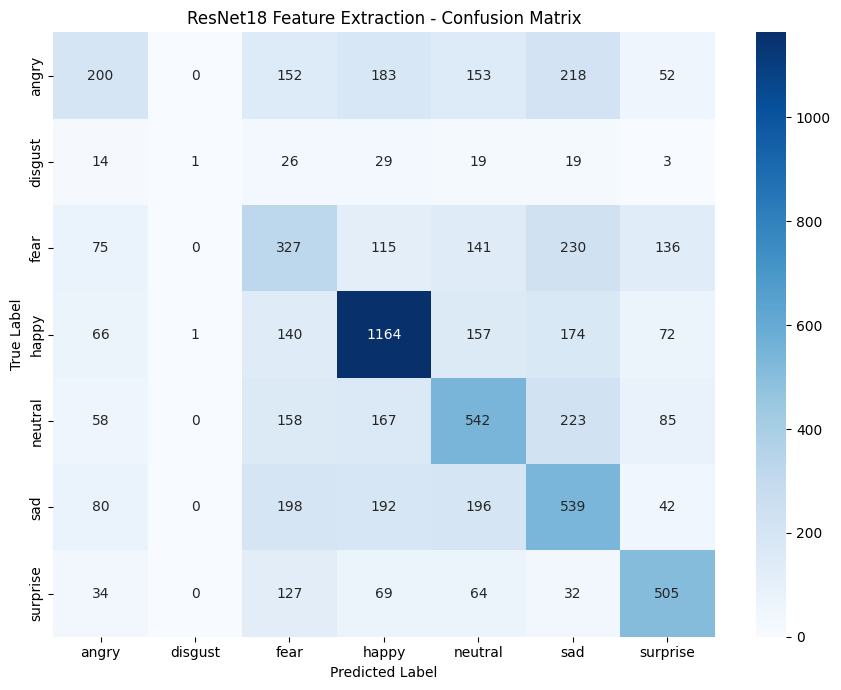


Feature Extraction evaluation completed!


In [24]:

# ==========================================
# 15. Evaluate ResNet18 Feature Extraction
# Test Accuracy, Precision, Recall, F1
# ==========================================

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------
# 1. Load Best Feature Extraction Model
# ------------------------------------------

BEST_FEATURE_PATH = (
    "/content/drive/MyDrive/FER2013_Models/"
    "best_resnet18_feature_extraction.pth"
)

if not os.path.exists(BEST_FEATURE_PATH):
    raise FileNotFoundError(
        "Best Feature Extraction model not found. "
        "Complete Step 13 first."
    )

best_state = torch.load(
    BEST_FEATURE_PATH,
    map_location=device,
    weights_only=True
)

resnet_model.load_state_dict(best_state)
resnet_model = resnet_model.to(device)
resnet_model.eval()

# ------------------------------------------
# 2. Evaluate on Test Data
# ------------------------------------------

criterion = nn.CrossEntropyLoss()

test_loss_total = 0.0
feature_true = []
feature_pred = []

with torch.no_grad():
    for images, labels in resnet_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_model(images)
        loss = criterion(outputs, labels)

        test_loss_total += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        feature_true.extend(
            labels.cpu().numpy()
        )

        feature_pred.extend(
            predictions.cpu().numpy()
        )

# ------------------------------------------
# 3. Calculate Evaluation Metrics
# ------------------------------------------

feature_test_loss = (
    test_loss_total / len(resnet_test_loader.dataset)
)

feature_accuracy = accuracy_score(
    feature_true, feature_pred
)

feature_precision = precision_score(
    feature_true,
    feature_pred,
    average="macro",
    zero_division=0
)

feature_recall = recall_score(
    feature_true,
    feature_pred,
    average="macro",
    zero_division=0
)

feature_f1 = f1_score(
    feature_true,
    feature_pred,
    average="macro",
    zero_division=0
)

print("ResNet18 Feature Extraction - Test Results")
print("=" * 45)

print(f"Test Loss:       {feature_test_loss:.4f}")
print(f"Accuracy:        {feature_accuracy * 100:.2f}%")
print(f"Macro Precision: {feature_precision * 100:.2f}%")
print(f"Macro Recall:    {feature_recall * 100:.2f}%")
print(f"Macro F1-score:  {feature_f1 * 100:.2f}%")

# ------------------------------------------
# 4. Classification Report
# ------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        feature_true,
        feature_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------
# 5. Confusion Matrix
# ------------------------------------------

cm = confusion_matrix(
    feature_true,
    feature_pred,
    labels=list(range(len(CLASS_NAMES)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("ResNet18 Feature Extraction - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. Save Metrics for Final Comparison
# ------------------------------------------

feature_metrics = {
    "Model": "ResNet18 Feature Extraction",
    "Accuracy": feature_accuracy,
    "Precision": feature_precision,
    "Recall": feature_recall,
    "F1": feature_f1,
    "Test Loss": feature_test_loss
}

print("\nFeature Extraction evaluation completed!")


In [25]:
print("ResNet18 model:", type(resnet_model).__name__)

print("Number of test samples:", len(all_labels))
print("Number of predictions:", len(all_predictions))

print("\nPrediction distribution:")
import numpy as np

print(np.bincount(all_predictions, minlength=len(CLASS_NAMES)))

print("\nTrue label distribution:")
print(np.bincount(all_labels, minlength=len(CLASS_NAMES)))

ResNet18 model: ResNet
Number of test samples: 7178
Number of predictions: 7178

Prediction distribution:
[ 902    0  469 1881 1309 1766  851]

True label distribution:
[ 958  111 1024 1774 1233 1247  831]


In [26]:

import os
from google.colab import drive

drive.mount('/content/drive')

# Search for saved ResNet18 models
for root, dirs, files in os.walk(
    "/content/drive/MyDrive"
):
    for file in files:
        if file.endswith((".pth", ".pt")):
            if "resnet" in file.lower():
                print(os.path.join(root, file))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/FER2013_Models/best_resnet18.pth
/content/drive/MyDrive/FER2013_Models/resnet18_checkpoint.pth
/content/drive/MyDrive/FER2013_Models/best_resnet18_feature_extraction.pth
/content/drive/MyDrive/FER2013_Models/resnet18_feature_extraction_checkpoint.pth
/content/drive/MyDrive/FER2013_Models/best_resnet18_partial_finetuning.pth
/content/drive/MyDrive/FER2013_Models/resnet18_partial_finetuning_checkpoint.pth
/content/drive/MyDrive/FER2013_Models/best_resnet18_full_finetuning_new.pth
/content/drive/MyDrive/FER2013_Models/resnet18_full_finetuning_new_checkpoint.pth
/content/drive/MyDrive/FER2013_Models/best_resnet18_accuracy_optimized.pth
/content/drive/MyDrive/FER2013_Models/resnet18_accuracy_optimized_checkpoint.pth
/content/drive/MyDrive/FER2013_Models/best_resnet18_regularized.pth
/content/drive/MyDrive/FER2013_Models/resnet18_regularized_

## 6 . Partial Fine-Tuning

We partially fine-tune ResNet18 by unfreezing Layer4 and the final classification layer while keeping the earlier layers frozen.

**This section includes:**
- Configure the model to train Layer4 and the final classification layer.
- Set up the optimizer and training process for the unfrozen layers.
- Train the model and save checkpoints to support resuming.
- Evaluate the fine-tuned model on the test dataset.
- Review classification metrics and the confusion matrix.

<div dir="rtl">

## 6 . الضبط الدقيق الجزئي

نضبط نموذج ResNet18 جزئيًا من خلال فك تجميد Layer4 وطبقة التصنيف الأخيرة، مع إبقاء الطبقات السابقة مجمّدة.

**تشمل هذه المرحلة:**
- إعداد النموذج لتدريب Layer4 وطبقة التصنيف الأخيرة.
- تهيئة المحسّن وعملية التدريب للطبقات التي تم فك تجميدها.
- تدريب النموذج وحفظ نقاط الاستكمال لمتابعة التدريب لاحقًا.
- تقييم النموذج بعد الضبط الدقيق باستخدام بيانات الاختبار.
- مراجعة مقاييس التصنيف ومصفوفة الالتباس.

</div>

In [27]:

# ==========================================
# 16. Partial Fine-Tuning Setup
# ResNet18 - Unfreeze Layer4 + FC
# ==========================================

import os
import torch
import torch.nn as nn
import torch.optim as optim
# Number of emotion classes
NUM_CLASSES = 7

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

from torchvision.models import resnet18

# 1. Load best Feature Extraction weights
FEATURE_PATH = (
    "/content/drive/MyDrive/FER2013_Models/"
    "best_resnet18_feature_extraction.pth"
)

if not os.path.exists(FEATURE_PATH):
    raise FileNotFoundError(
        "Feature Extraction model not found."
    )

# 2. Create a separate model
partial_model = resnet18(weights=None)

partial_model.fc = nn.Linear(
    partial_model.fc.in_features,
    NUM_CLASSES
)

partial_model.load_state_dict(
    torch.load(
        FEATURE_PATH,
        map_location=device,
        weights_only=True
    )
)

partial_model = partial_model.to(device)

# 3. Freeze all layers
for param in partial_model.parameters():
    param.requires_grad = False

# 4. Unfreeze Layer4
for param in partial_model.layer4.parameters():
    param.requires_grad = True

# 5. Unfreeze FC
for param in partial_model.fc.parameters():
    param.requires_grad = True

# 6. Loss function
partial_criterion = nn.CrossEntropyLoss()

# 7. Optimizer with separate learning rates
partial_optimizer = optim.AdamW(
    [
        {
            "params": partial_model.layer4.parameters(),
            "lr": 0.00001
        },
        {
            "params": partial_model.fc.parameters(),
            "lr": 0.0001
        }
    ],
    weight_decay=0.0001
)

# 8. Learning rate scheduler
partial_scheduler = (
    optim.lr_scheduler.ReduceLROnPlateau(
        partial_optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )
)

# 9. Training mode helper
def set_partial_training_mode():
    partial_model.train()

    # Keep frozen BatchNorm statistics fixed
    for module in partial_model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

# 10. Verify configuration
trainable_params = sum(
    p.numel()
    for p in partial_model.parameters()
    if p.requires_grad
)

print("Partial Fine-Tuning configured!")
print("Trainable: Layer4 + FC")
print("Trainable parameters:", trainable_params)
print("Device:", device)
print("Feature Extraction model preserved.")


Partial Fine-Tuning configured!
Trainable: Layer4 + FC
Trainable parameters: 8397319
Device: cuda
Feature Extraction model preserved.


In [28]:

# ==========================================
# Step 17 - Partial Fine-Tuning Training
# ResNet18: Layer4 + FC
# Auto Save + Resume
# ==========================================

import os
import torch
import torch.nn as nn
from tqdm.auto import tqdm

SAVE_DIR = "/content/drive/MyDrive/FER2013_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

PARTIAL_BEST_PATH = os.path.join(
    SAVE_DIR, "best_resnet18_partial_finetuning.pth"
)

PARTIAL_CHECKPOINT_PATH = os.path.join(
    SAVE_DIR, "resnet18_partial_finetuning_checkpoint.pth"
)

PARTIAL_EPOCHS = 10

partial_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_partial_acc = -1.0
start_epoch = 0

# ------------------------------------------
# 1. Resume previous training if available
# ------------------------------------------

if os.path.exists(PARTIAL_CHECKPOINT_PATH):

    checkpoint = torch.load(
        PARTIAL_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    partial_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    partial_optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    partial_scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    partial_history = checkpoint["history"]
    best_partial_acc = checkpoint["best_val_acc"]
    start_epoch = checkpoint["epoch"] + 1

    print(f"Resuming from Epoch {start_epoch + 1}")

else:
    print("Starting new Partial Fine-Tuning training")

# ------------------------------------------
# 2. Training loop
# ------------------------------------------

for epoch in range(start_epoch, PARTIAL_EPOCHS):

    set_partial_training_mode()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        resnet_train_loader,
        desc=f"Epoch {epoch + 1}/{PARTIAL_EPOCHS} - Train"
    ):

        images = images.to(device)
        labels = labels.to(device)

        partial_optimizer.zero_grad()

        outputs = partial_model(images)
        loss = partial_criterion(outputs, labels)

        loss.backward()
        partial_optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # --------------------------------------
    # 3. Validation
    # --------------------------------------

    partial_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in tqdm(
            resnet_val_loader,
            desc=f"Epoch {epoch + 1}/{PARTIAL_EPOCHS} - Val"
        ):

            images = images.to(device)
            labels = labels.to(device)

            outputs = partial_model(images)
            loss = partial_criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    partial_scheduler.step(val_loss)

    # --------------------------------------
    # 4. Save history
    # --------------------------------------

    partial_history["train_loss"].append(train_loss)
    partial_history["train_acc"].append(train_acc)
    partial_history["val_loss"].append(val_loss)
    partial_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{PARTIAL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc * 100:.2f}%"
    )

    # --------------------------------------
    # 5. Save best model
    # --------------------------------------

    if val_acc > best_partial_acc:

        best_partial_acc = val_acc

        torch.save(
            partial_model.state_dict(),
            PARTIAL_BEST_PATH
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_partial_acc * 100:.2f}%"
        )

    # --------------------------------------
    # 6. Save checkpoint after each epoch
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": partial_model.state_dict(),
            "optimizer_state_dict": partial_optimizer.state_dict(),
            "scheduler_state_dict": partial_scheduler.state_dict(),
            "best_val_acc": best_partial_acc,
            "history": partial_history,
            "training_stage": "partial_finetuning"
        },
        PARTIAL_CHECKPOINT_PATH
    )

    print("Checkpoint saved.\n")

# ------------------------------------------
# 7. Load best model after training
# ------------------------------------------

partial_model.load_state_dict(
    torch.load(
        PARTIAL_BEST_PATH,
        map_location=device,
        weights_only=True
    )
)

partial_model.eval()

print("=" * 45)
print("Partial Fine-Tuning Completed!")
print(f"Best Validation Accuracy: {best_partial_acc * 100:.2f}%")
print("Best Model:", PARTIAL_BEST_PATH)
print("=" * 45)


Resuming from Epoch 11
Partial Fine-Tuning Completed!
Best Validation Accuracy: 60.80%
Best Model: /content/drive/MyDrive/FER2013_Models/best_resnet18_partial_finetuning.pth


Partial Fine-Tuning Test Results
Test Loss: 1.0822
Accuracy:  60.24%
Precision: 58.15%
Recall:    54.67%
F1-score:  55.62%

Classification Report:
              precision    recall  f1-score   support

       angry       0.46      0.57      0.51       958
     disgust       0.53      0.28      0.36       111
        fear       0.46      0.39      0.42      1024
       happy       0.86      0.79      0.83      1774
     neutral       0.53      0.64      0.58      1233
         sad       0.50      0.46      0.48      1247
    surprise       0.74      0.69      0.71       831

    accuracy                           0.60      7178
   macro avg       0.58      0.55      0.56      7178
weighted avg       0.61      0.60      0.60      7178



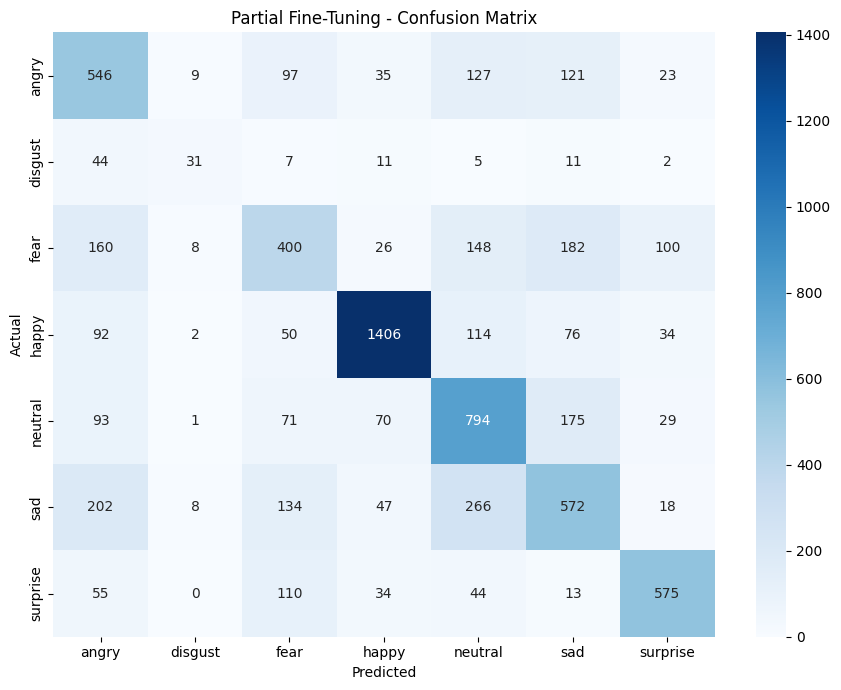

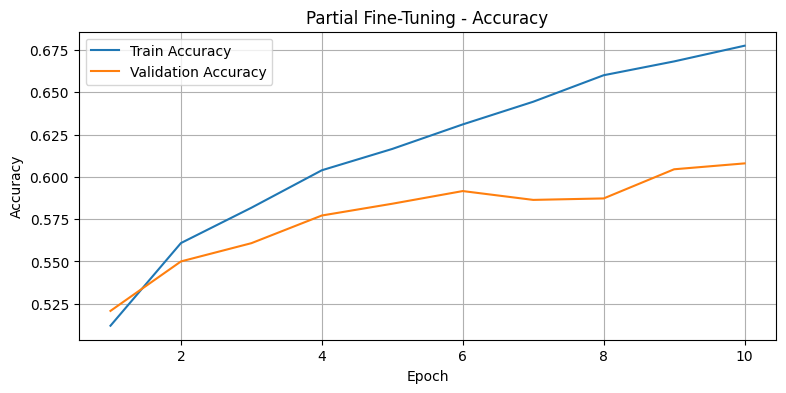

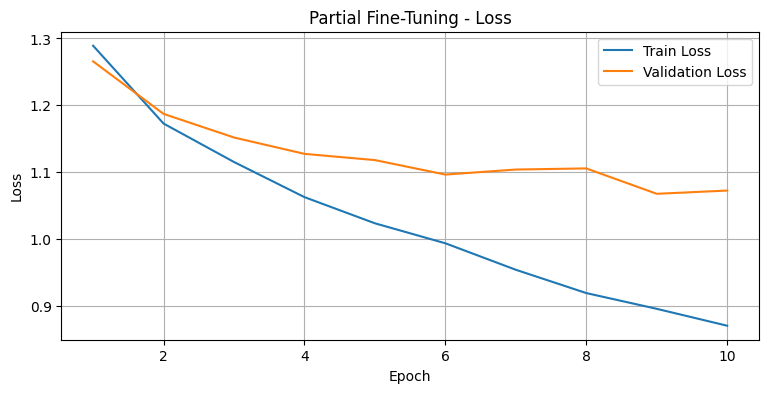

In [29]:

# ==========================================
# Step 18 - Partial Fine-Tuning Evaluation
# ==========================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best saved Partial Fine-Tuning model
partial_model.load_state_dict(
    torch.load(
        PARTIAL_BEST_PATH,
        map_location=device,
        weights_only=True
    )
)

partial_model.eval()

partial_true = []
partial_pred = []

test_loss_sum = 0.0
test_total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = partial_model(images)
        loss = partial_criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        partial_true.extend(labels.cpu().numpy())
        partial_pred.extend(predictions.cpu().numpy())

        test_loss_sum += loss.item() * labels.size(0)
        test_total += labels.size(0)

# Metrics
partial_accuracy = accuracy_score(
    partial_true, partial_pred
)
partial_precision = precision_score(
    partial_true, partial_pred,
    average="macro", zero_division=0
)
partial_recall = recall_score(
    partial_true, partial_pred,
    average="macro", zero_division=0
)
partial_f1 = f1_score(
    partial_true, partial_pred,
    average="macro", zero_division=0
)

partial_metrics = {
    "accuracy": partial_accuracy,
    "precision": partial_precision,
    "recall": partial_recall,
    "f1": partial_f1
}

print("Partial Fine-Tuning Test Results")
print("=" * 40)
print(f"Test Loss: {test_loss_sum / test_total:.4f}")
print(f"Accuracy:  {partial_accuracy * 100:.2f}%")
print(f"Precision: {partial_precision * 100:.2f}%")
print(f"Recall:    {partial_recall * 100:.2f}%")
print(f"F1-score:  {partial_f1 * 100:.2f}%")

class_names = [
    "angry", "disgust", "fear", "happy",
    "neutral", "sad", "surprise"
]

print("\nClassification Report:")
print(classification_report(
    partial_true,
    partial_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    partial_true,
    partial_pred,
    labels=list(range(7))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Partial Fine-Tuning - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Accuracy graph
epochs = range(1, len(partial_history["train_acc"]) + 1)

plt.figure(figsize=(9, 4))
plt.plot(
    epochs, partial_history["train_acc"],
    label="Train Accuracy"
)
plt.plot(
    epochs, partial_history["val_acc"],
    label="Validation Accuracy"
)
plt.title("Partial Fine-Tuning - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(9, 4))
plt.plot(
    epochs, partial_history["train_loss"],
    label="Train Loss"
)
plt.plot(
    epochs, partial_history["val_loss"],
    label="Validation Loss"
)
plt.title("Partial Fine-Tuning - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


##7 .  Full Fine-Tuning

We fine-tune the pretrained ResNet18 model by allowing all its layers to update during training.

**This section includes:**
- Load and configure ResNet18 for full fine-tuning.
- Unfreeze all model layers for training.
- Train the model and save progress automatically for resuming.
- Evaluate the final model on the test dataset.
- Review classification metrics and the confusion matrix.

<div dir="rtl">

##7 .  الضبط الدقيق الكامل

نضبط نموذج ResNet18 المدرّب مسبقًا من خلال السماح لجميع طبقاته بالتحديث أثناء التدريب.

**تشمل هذه المرحلة:**
- تحميل نموذج ResNet18 وتهيئته للضبط الدقيق الكامل.
- فك تجميد جميع طبقات النموذج لتدريبها.
- تدريب النموذج وحفظ التقدم تلقائيًا لإمكانية استكمال التدريب.
- تقييم النموذج النهائي باستخدام بيانات الاختبار.
- مراجعة مقاييس التصنيف ومصفوفة الالتباس.

</div>

In [30]:

# ==========================================
# Step 19 - Full Fine-Tuning Setup
# ResNet18 - Train ALL Layers
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 7
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# New independent model
full_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

full_model.fc = nn.Linear(
    full_model.fc.in_features,
    NUM_CLASSES
)

# Unfreeze ALL layers
for param in full_model.parameters():
    param.requires_grad = True

full_model = full_model.to(device)

# Loss function
full_criterion = nn.CrossEntropyLoss()

# Optimizer
full_optimizer = optim.Adam(
    full_model.parameters(),
    lr=0.0001
)

# Scheduler
full_scheduler = (
    optim.lr_scheduler.ReduceLROnPlateau(
        full_optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )
)

print("Full Fine-Tuning configured!")
print("All ResNet18 layers are trainable.")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in full_model.parameters()
        if p.requires_grad
    )
)


Full Fine-Tuning configured!
All ResNet18 layers are trainable.
Device: cuda
Trainable parameters: 11180103


In [31]:

# ==========================================
# Step 20 - Full Fine-Tuning Training
# Auto Save + Resume
# ==========================================

import os
import torch
from tqdm.auto import tqdm

SAVE_DIR = "/content/drive/MyDrive/FER2013_Models"
os.makedirs(SAVE_DIR, exist_ok=True)

FULL_BEST_PATH = os.path.join(
    SAVE_DIR, "best_resnet18_full_finetuning_new.pth"
)

FULL_CHECKPOINT_PATH = os.path.join(
    SAVE_DIR, "resnet18_full_finetuning_new_checkpoint.pth"
)

FULL_EPOCHS = 10

full_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_full_acc = -1.0
start_epoch = 0

# Resume saved training
if os.path.exists(FULL_CHECKPOINT_PATH):
    checkpoint = torch.load(
        FULL_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    if checkpoint.get("training_stage") != "full_finetuning":
        raise ValueError("Wrong checkpoint stage!")

    full_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
    full_optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )
    full_scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    full_history = checkpoint["history"]
    best_full_acc = checkpoint["best_val_acc"]
    start_epoch = checkpoint["epoch"] + 1

    print(f"Resuming from Epoch {start_epoch + 1}")
else:
    print("Starting new Full Fine-Tuning training")

# Training
for epoch in range(start_epoch, FULL_EPOCHS):

    full_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        resnet_train_loader,
        desc=f"Epoch {epoch+1}/{FULL_EPOCHS} - Train"
    ):
        images = images.to(device)
        labels = labels.to(device)

        full_optimizer.zero_grad()

        outputs = full_model(images)
        loss = full_criterion(outputs, labels)

        loss.backward()
        full_optimizer.step()

        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += n

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    full_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            resnet_val_loader,
            desc=f"Epoch {epoch+1}/{FULL_EPOCHS} - Val"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = full_model(images)
            loss = full_criterion(outputs, labels)

            n = labels.size(0)
            val_loss_sum += loss.item() * n
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += n

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    full_scheduler.step(val_loss)

    full_history["train_loss"].append(train_loss)
    full_history["train_acc"].append(train_acc)
    full_history["val_loss"].append(val_loss)
    full_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{FULL_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    # Save best model
    if val_acc > best_full_acc:
        best_full_acc = val_acc

        torch.save(
            full_model.state_dict(),
            FULL_BEST_PATH
        )

        print(
            f"Best model saved! "
            f"Val Accuracy: {best_full_acc*100:.2f}%"
        )

    # Save checkpoint
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": full_model.state_dict(),
            "optimizer_state_dict": full_optimizer.state_dict(),
            "scheduler_state_dict": full_scheduler.state_dict(),
            "best_val_acc": best_full_acc,
            "history": full_history,
            "training_stage": "full_finetuning"
        },
        FULL_CHECKPOINT_PATH
    )

    print("Checkpoint saved.\n")

# Restore best model
full_model.load_state_dict(
    torch.load(
        FULL_BEST_PATH,
        map_location=device,
        weights_only=True
    )
)

full_model.eval()

print("=" * 45)
print("Full Fine-Tuning Completed!")
print(f"Best Validation Accuracy: {best_full_acc*100:.2f}%")
print("Best Model:", FULL_BEST_PATH)
print("=" * 45)


Resuming from Epoch 11
Full Fine-Tuning Completed!
Best Validation Accuracy: 68.36%
Best Model: /content/drive/MyDrive/FER2013_Models/best_resnet18_full_finetuning_new.pth


Full Fine-Tuning Test Results
Test Loss: 1.0023
Accuracy:  68.45%
Precision: 68.41%
Recall:    65.78%
F1-score:  66.66%

Classification Report:
              precision    recall  f1-score   support

       angry       0.63      0.61      0.62       958
     disgust       0.76      0.59      0.66       111
        fear       0.61      0.44      0.51      1024
       happy       0.88      0.88      0.88      1774
     neutral       0.59      0.69      0.64      1233
         sad       0.54      0.58      0.56      1247
    surprise       0.77      0.83      0.80       831

    accuracy                           0.68      7178
   macro avg       0.68      0.66      0.67      7178
weighted avg       0.69      0.68      0.68      7178



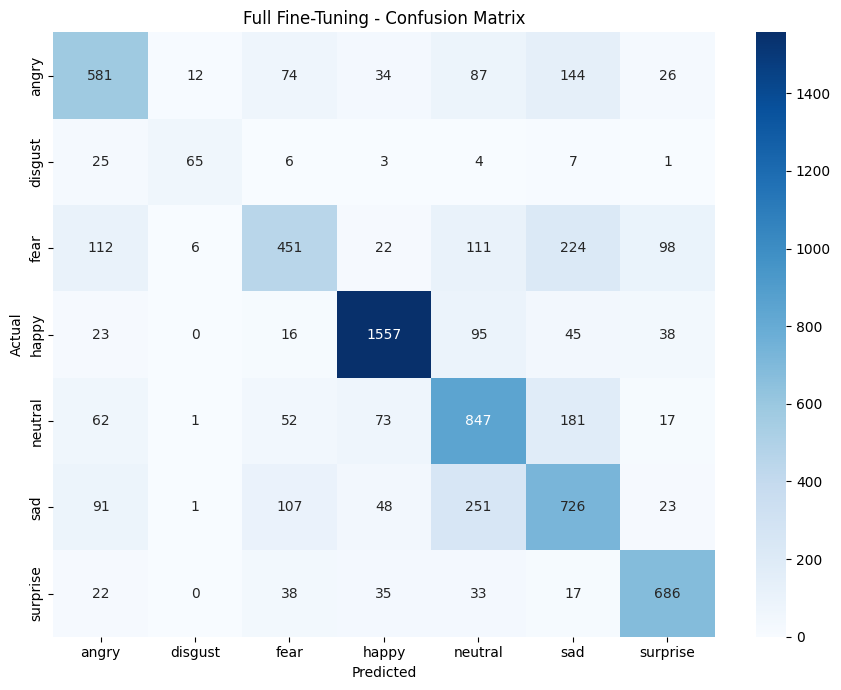

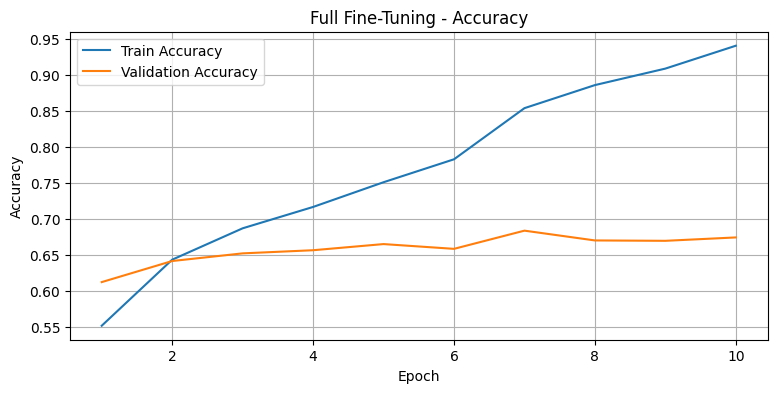

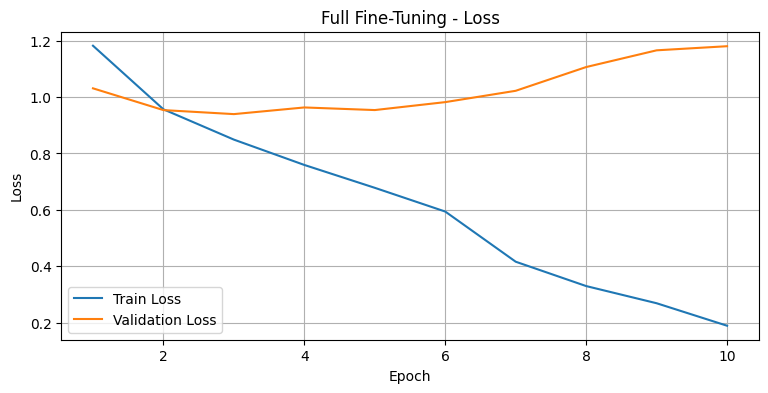

In [32]:

# ==========================================
# Step 21 - Full Fine-Tuning Evaluation
# ==========================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best Full Fine-Tuning model
full_model.load_state_dict(
    torch.load(
        FULL_BEST_PATH,
        map_location=device,
        weights_only=True
    )
)

full_model.eval()

full_true = []
full_pred = []
full_test_loss_sum = 0.0
full_test_total = 0

with torch.no_grad():
    for images, labels in resnet_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = full_model(images)
        loss = full_criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        full_true.extend(labels.cpu().numpy())
        full_pred.extend(predictions.cpu().numpy())

        full_test_loss_sum += loss.item() * labels.size(0)
        full_test_total += labels.size(0)

# Evaluation metrics
full_accuracy = accuracy_score(full_true, full_pred)
full_precision = precision_score(
    full_true, full_pred,
    average="macro", zero_division=0
)
full_recall = recall_score(
    full_true, full_pred,
    average="macro", zero_division=0
)
full_f1 = f1_score(
    full_true, full_pred,
    average="macro", zero_division=0
)

full_metrics = {
    "accuracy": full_accuracy,
    "precision": full_precision,
    "recall": full_recall,
    "f1": full_f1
}

print("Full Fine-Tuning Test Results")
print("=" * 40)
print(f"Test Loss: {full_test_loss_sum/full_test_total:.4f}")
print(f"Accuracy:  {full_accuracy*100:.2f}%")
print(f"Precision: {full_precision*100:.2f}%")
print(f"Recall:    {full_recall*100:.2f}%")
print(f"F1-score:  {full_f1*100:.2f}%")

class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

print("\nClassification Report:")
print(classification_report(
    full_true,
    full_pred,
    labels=list(range(7)),
    target_names=class_names,
    zero_division=0
))

# 1. Confusion Matrix
cm = confusion_matrix(
    full_true,
    full_pred,
    labels=list(range(7))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Full Fine-Tuning - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 2. Accuracy Graph
epochs = range(1, len(full_history["train_acc"]) + 1)

plt.figure(figsize=(9, 4))
plt.plot(
    epochs,
    full_history["train_acc"],
    label="Train Accuracy"
)
plt.plot(
    epochs,
    full_history["val_acc"],
    label="Validation Accuracy"
)
plt.title("Full Fine-Tuning - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 3. Loss Graph
plt.figure(figsize=(9, 4))
plt.plot(
    epochs,
    full_history["train_loss"],
    label="Train Loss"
)
plt.plot(
    epochs,
    full_history["val_loss"],
    label="Validation Loss"
)
plt.title("Full Fine-Tuning - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


## 8 . Model Comparison

We compare the CNN and ResNet18 approaches using consistent evaluation metrics to understand their relative performance.

**This section includes:**
- Collect the evaluation results for the trained models.
- Compare accuracy, precision, recall, and F1-score.
- Present the results in a comparison table or chart.
- Use the metrics to identify the model with the strongest overall performance.

<div dir="rtl">

## 8 . مقارنة النماذج

نقارن بين نموذج CNN ونماذج ResNet18 باستخدام مقاييس تقييم موحّدة لفهم الفروقات في الأداء.

**تشمل هذه المرحلة:**
- جمع نتائج تقييم النماذج المدرّبة.
- مقارنة الدقة (Accuracy) والإحكام (Precision) والاستدعاء (Recall) ودرجة F1.
- عرض النتائج في جدول أو رسم للمقارنة.
- استخدام المقاييس لتحديد النموذج الأفضل من حيث الأداء العام.

</div>

FER2013 - Model Comparison


,accuracy,precision,recall,f1
CNN,61.34,50.95,51.13,50.16
Transfer Learning,45.67,44.88,38.18,37.73
Partial Fine-Tuning,60.24,58.15,54.67,55.62
Full Fine-Tuning,68.45,68.41,65.78,66.66


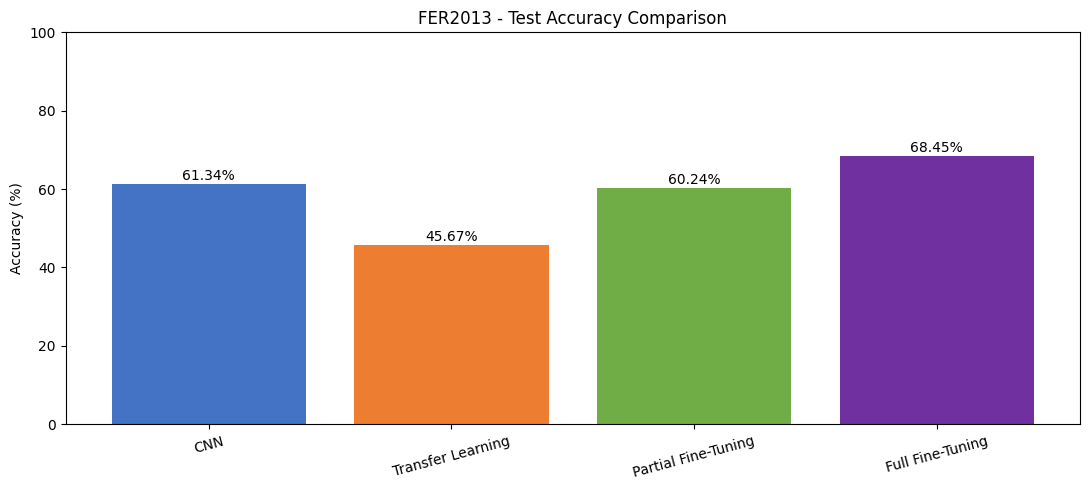

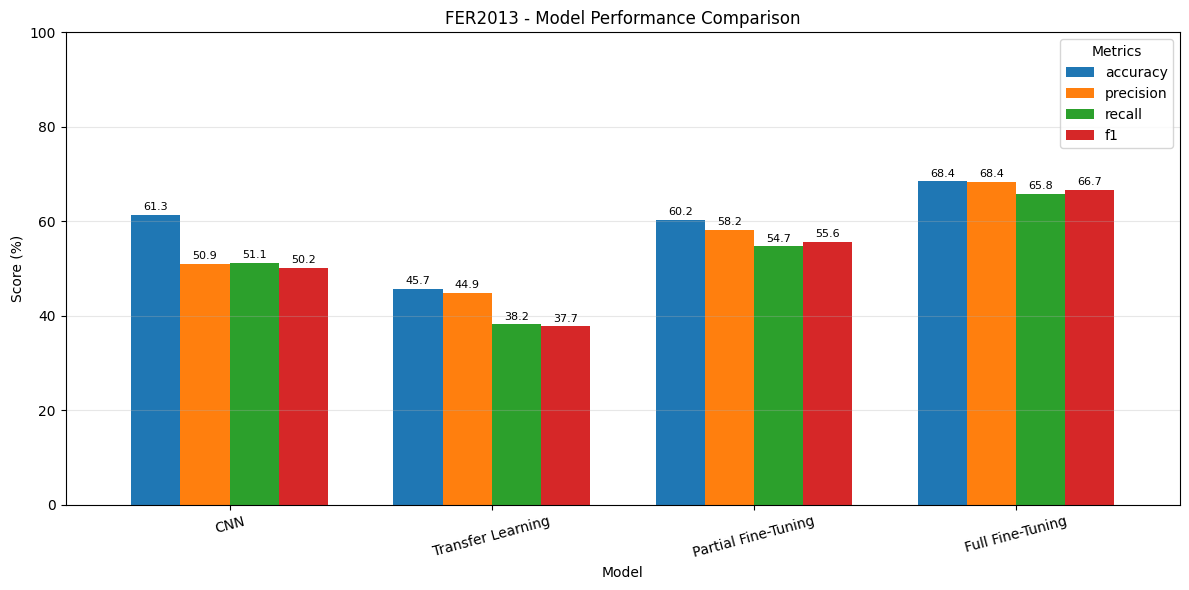

Best Model: Full Fine-Tuning
Test Accuracy: 68.45%


In [33]:

# ==========================================
# Step 22 - Model Comparison
# Accuracy, Precision, Recall, F1-score
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------
# 1. CNN Test Results
# ------------------------------------------

cnn_metrics = {
    "accuracy": 0.6134,
    "precision": 0.5095,
    "recall": 0.5113,
    "f1": 0.5016
}

# ------------------------------------------
# 2. Transfer Learning Metrics
# Fix missing / NaN values
# ------------------------------------------

if (
    "feature_true" in globals()
    and "feature_pred" in globals()
    and len(feature_true) > 0
):
    feature_metrics = {
        "accuracy": accuracy_score(
            feature_true, feature_pred
        ),
        "precision": precision_score(
            feature_true, feature_pred,
            average="macro", zero_division=0
        ),
        "recall": recall_score(
            feature_true, feature_pred,
            average="macro", zero_division=0
        ),
        "f1": f1_score(
            feature_true, feature_pred,
            average="macro", zero_division=0
        )
    }
else:
    raise RuntimeError(
        "Transfer Learning predictions are missing. "
        "Run Step 15 (Evaluation only), then rerun Step 22."
    )

# ------------------------------------------
# 3. Collect All Model Results
# ------------------------------------------

models_results = {
    "CNN": cnn_metrics,
    "Transfer Learning": feature_metrics,
    "Partial Fine-Tuning": partial_metrics,
    "Full Fine-Tuning": full_metrics
}

comparison_df = pd.DataFrame(models_results).T

comparison_df = comparison_df[
    ["accuracy", "precision", "recall", "f1"]
].apply(pd.to_numeric, errors="coerce")

# Check for missing metrics
if comparison_df.isna().any().any():
    raise ValueError(
        "Some model metrics are missing. "
        "Check the previous evaluation steps."
    )

comparison_percent = comparison_df * 100

# ------------------------------------------
# 4. Comparison Table
# ------------------------------------------

print("FER2013 - Model Comparison")
display(comparison_percent.round(2))

# ------------------------------------------
# 5. Accuracy Comparison
# ------------------------------------------

plt.figure(figsize=(11, 5))

bars = plt.bar(
    comparison_percent.index,
    comparison_percent["accuracy"],
    color=["#4472C4", "#ED7D31", "#70AD47", "#7030A0"]
)

plt.title("FER2013 - Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. All Metrics Comparison
# ------------------------------------------

ax = comparison_percent.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("FER2013 - Model Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=2,
        fontsize=8
    )

plt.tight_layout()
plt.show()

# ------------------------------------------
# 7. Select Best Model
# ------------------------------------------

best_model_name = comparison_df["accuracy"].idxmax()
best_accuracy = comparison_df.loc[
    best_model_name, "accuracy"
]

print("=" * 45)
print("Best Model:", best_model_name)
print(f"Test Accuracy: {best_accuracy * 100:.2f}%")
print("=" * 45)


## 9 . Model Optimization

We optimize the trained model by converting its weights to FP16, then examine the trade-off between model size, inference speed, and predictive performance.

**This section includes:**
- Convert the selected model weights to FP16.
- Save the optimized model for later use.
- Benchmark inference speed for the original and FP16 models.
- Evaluate the optimized model and compare its results with the original model.

<div dir="rtl">

##9 . تحسين النموذج

نحسّن النموذج المدرّب بتحويل أوزانه إلى FP16، ثم نفحص التوازن بين حجم النموذج وسرعة التنبؤ وأداء التصنيف.

**تشمل هذه المرحلة:**
- تحويل أوزان النموذج المختار إلى FP16.
- حفظ النموذج المحسّن لاستخدامه لاحقًا.
- قياس سرعة التنبؤ للنموذج الأصلي ونموذج FP16.
- تقييم النموذج المحسّن ومقارنة نتائجه بالنموذج الأصلي.

</div>

In [34]:
# ==========================================
# Step 23.1 — Model Optimization (FP16)
# ==========================================

import os
import time
import torch
import torch.nn as nn
from torchvision import models

# Paths
MODEL_DIR = "/content/drive/MyDrive/FER2013_Models"

ORIGINAL_PATH = os.path.join(
    MODEL_DIR,
    "best_resnet18_full_finetuning_new.pth"
)

OPTIMIZED_PATH = os.path.join(
    MODEL_DIR,
    "best_resnet18_full_finetuning_fp16.pth"
)

# Load original best model
original_model = models.resnet18(weights=None)
original_model.fc = nn.Linear(
    original_model.fc.in_features, 7
)

original_model.load_state_dict(
    torch.load(
        ORIGINAL_PATH,
        map_location="cpu",
        weights_only=True
    )
)

original_model.eval()

# Convert weights to FP16
optimized_model = models.resnet18(weights=None)
optimized_model.fc = nn.Linear(
    optimized_model.fc.in_features, 7
)

optimized_model.load_state_dict(
    original_model.state_dict()
)

optimized_model = optimized_model.half()
optimized_model.eval()

# Save optimized model (separate file)
torch.save(
    optimized_model.state_dict(),
    OPTIMIZED_PATH
)

# Compare file sizes
original_size = os.path.getsize(ORIGINAL_PATH) / (1024 ** 2)
optimized_size = os.path.getsize(OPTIMIZED_PATH) / (1024 ** 2)

reduction = (
    (original_size - optimized_size) / original_size
) * 100

print("Model Optimization Completed!")
print("-" * 45)

print(f"Original Model Size:  {original_size:.2f} MB")
print(f"Optimized Model Size: {optimized_size:.2f} MB")
print(f"Size Reduction:       {reduction:.2f}%")

print("-" * 45)
print("Optimized model saved at:")
print(OPTIMIZED_PATH)

Model Optimization Completed!
---------------------------------------------
Original Model Size:  42.73 MB
Optimized Model Size: 21.38 MB
Size Reduction:       49.95%
---------------------------------------------
Optimized model saved at:
/content/drive/MyDrive/FER2013_Models/best_resnet18_full_finetuning_fp16.pth


         Model  Inference Time (ms)
 Original FP32             2.739372
Optimized FP16             3.145482

Speedup: 0.87x


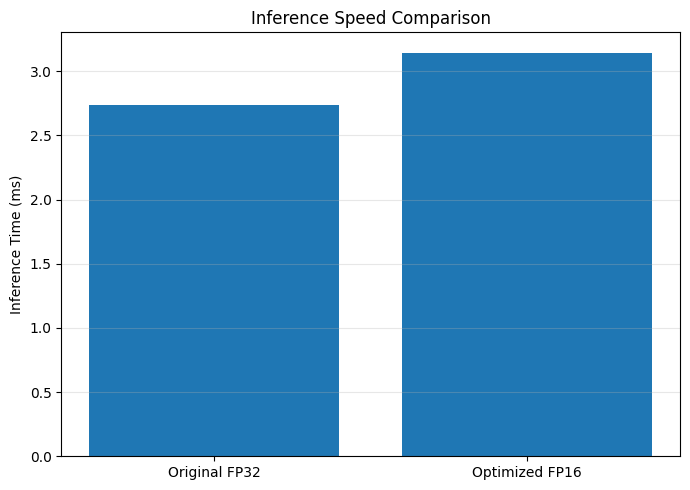

In [35]:
# ==========================================
# Step 23.2 — Inference Speed Comparison
# ==========================================

import time
import pandas as pd
import matplotlib.pyplot as plt

if torch.cuda.is_available():

    benchmark_device = torch.device("cuda")

    original_model = original_model.to(
        benchmark_device
    ).float()

    optimized_model = optimized_model.to(
        benchmark_device
    ).half()

    original_model.eval()
    optimized_model.eval()

    def measure_inference(model, dtype, runs=100):

        dummy_input = torch.randn(
            1, 3, 224, 224,
            device=benchmark_device,
            dtype=dtype
        )

        # Warm-up
        with torch.inference_mode():
            for _ in range(20):
                model(dummy_input)

        torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.inference_mode():
            for _ in range(runs):
                model(dummy_input)

        torch.cuda.synchronize()

        end = time.perf_counter()

        return ((end - start) / runs) * 1000

    original_time = measure_inference(
        original_model,
        torch.float32
    )

    optimized_time = measure_inference(
        optimized_model,
        torch.float16
    )

    speedup = original_time / optimized_time

    speed_df = pd.DataFrame({
        "Model": ["Original FP32", "Optimized FP16"],
        "Inference Time (ms)": [
            original_time,
            optimized_time
        ]
    })

    print(speed_df.to_string(index=False))

    print(f"\nSpeedup: {speedup:.2f}x")

    plt.figure(figsize=(7, 5))

    plt.bar(
        speed_df["Model"],
        speed_df["Inference Time (ms)"]
    )

    plt.title("Inference Speed Comparison")
    plt.ylabel("Inference Time (ms)")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("GPU is not available.")
    print("FP16 inference benchmark skipped.")
    print("Use a GPU runtime to compare inference speed.")

Evaluation Device: cuda

Evaluating Original FP32...
Evaluating Optimized FP16...

Model Evaluation Comparison (%)
   Metric  Original FP32  Optimized FP16
 Accuracy          68.45           68.45
Precision          68.41           68.42
   Recall          65.78           65.79
 F1 Score          66.66           66.67


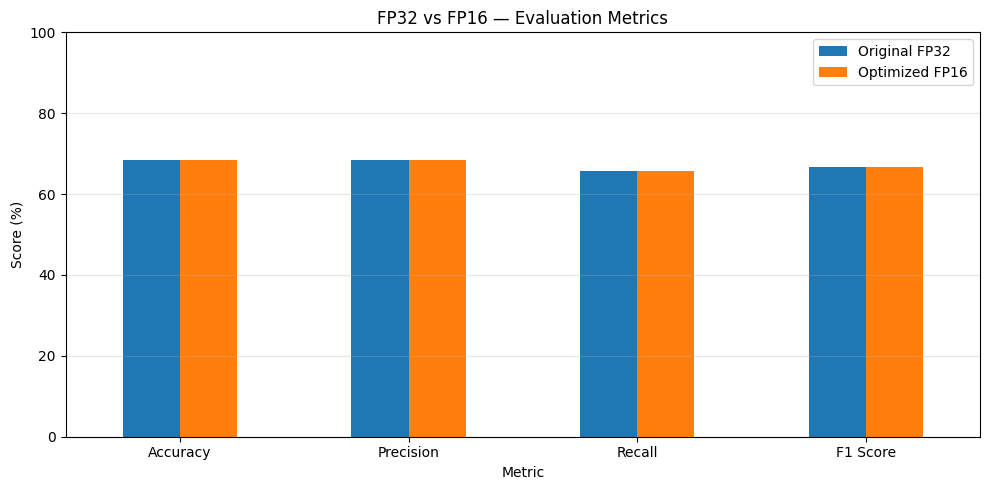

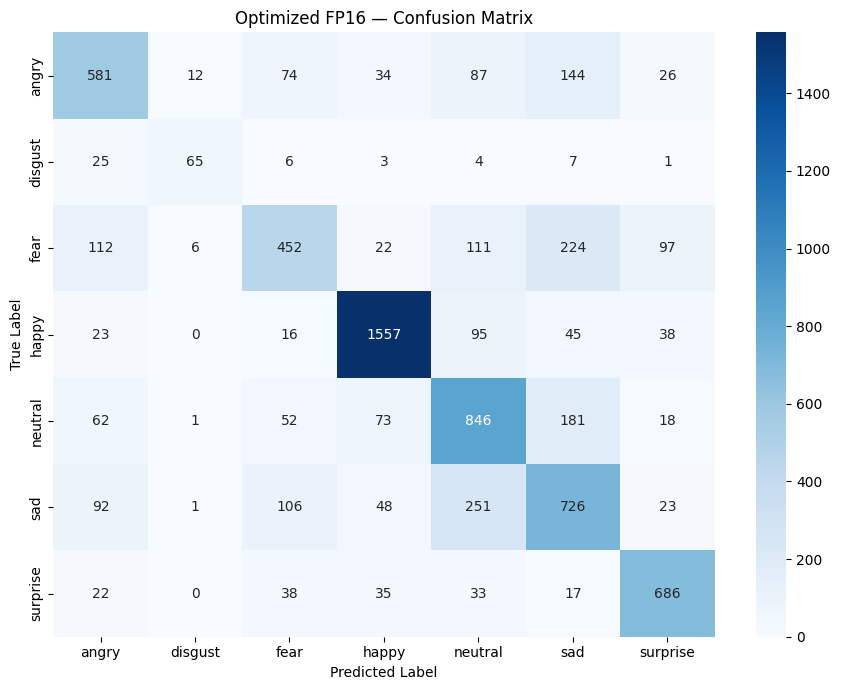


Optimized FP16 Classification Report:

              precision    recall  f1-score   support

       angry       0.63      0.61      0.62       958
     disgust       0.76      0.59      0.66       111
        fear       0.61      0.44      0.51      1024
       happy       0.88      0.88      0.88      1774
     neutral       0.59      0.69      0.64      1233
         sad       0.54      0.58      0.56      1247
    surprise       0.77      0.83      0.80       831

    accuracy                           0.68      7178
   macro avg       0.68      0.66      0.67      7178
weighted avg       0.69      0.68      0.68      7178


========== STEP 24 SUMMARY ==========
Original FP32 Accuracy: 68.45%
Optimized FP16 Accuracy: 68.45%
Accuracy Difference: +0.00 percentage points
Step 24 Completed!


In [36]:

# ==========================================
# Step 24 — Optimized Model Evaluation
# ==========================================

import os
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------
# 1. Settings
# ------------------------------------------

MODEL_DIR = "/content/drive/MyDrive/FER2013_Models"

FP32_PATH = os.path.join(
    MODEL_DIR,
    "best_resnet18_full_finetuning_new.pth"
)

FP16_PATH = os.path.join(
    MODEL_DIR,
    "best_resnet18_full_finetuning_fp16.pth"
)

class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

eval_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Evaluation Device:", eval_device)

# ------------------------------------------
# 2. Load Both Models
# ------------------------------------------

def load_resnet18_model(path, use_fp16=False):

    model = models.resnet18(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        len(class_names)
    )

    state_dict = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state_dict)

    model = model.to(eval_device)

    # FP16 convolution inference requires CUDA here.
    if use_fp16 and eval_device.type == "cuda":
        model = model.half()
    else:
        model = model.float()

    model.eval()

    return model


fp32_model = load_resnet18_model(
    FP32_PATH,
    use_fp16=False
)

fp16_model = load_resnet18_model(
    FP16_PATH,
    use_fp16=True
)

# ------------------------------------------
# 3. Evaluation Function
# ------------------------------------------

def evaluate_optimized_model(model, loader):

    all_true = []
    all_pred = []

    input_dtype = next(model.parameters()).dtype

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                device=eval_device,
                dtype=input_dtype
            )

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())

    metrics = {
        "Accuracy": accuracy_score(
            all_true, all_pred
        ),
        "Precision": precision_score(
            all_true, all_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            all_true, all_pred,
            average="macro",
            zero_division=0
        ),
        "F1 Score": f1_score(
            all_true, all_pred,
            average="macro",
            zero_division=0
        )
    }

    return metrics, all_true, all_pred


# ------------------------------------------
# 4. Evaluate FP32 and FP16
# ------------------------------------------

print("\nEvaluating Original FP32...")

fp32_metrics, fp32_true, fp32_pred = (
    evaluate_optimized_model(
        fp32_model,
        resnet_test_loader
    )
)

print("Evaluating Optimized FP16...")

fp16_metrics, fp16_true, fp16_pred = (
    evaluate_optimized_model(
        fp16_model,
        resnet_test_loader
    )
)

# ------------------------------------------
# 5. Comparison Table
# ------------------------------------------

comparison_24 = pd.DataFrame({
    "Metric": list(fp32_metrics.keys()),
    "Original FP32": [
        value * 100
        for value in fp32_metrics.values()
    ],
    "Optimized FP16": [
        value * 100
        for value in fp16_metrics.values()
    ]
})

print("\nModel Evaluation Comparison (%)")
print(
    comparison_24.round(2).to_string(index=False)
)

# ------------------------------------------
# 6. Metrics Comparison Chart
# ------------------------------------------

comparison_24.set_index("Metric")[
    ["Original FP32", "Optimized FP16"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("FP32 vs FP16 — Evaluation Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------
# 7. FP16 Confusion Matrix
# ------------------------------------------

cm = confusion_matrix(
    fp16_true,
    fp16_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Optimized FP16 — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ------------------------------------------
# 8. FP16 Classification Report
# ------------------------------------------

print("\nOptimized FP16 Classification Report:\n")

print(
    classification_report(
        fp16_true,
        fp16_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)

# ------------------------------------------
# 9. Final Summary
# ------------------------------------------

print("\n========== STEP 24 SUMMARY ==========")

print(
    f"Original FP32 Accuracy: "
    f"{fp32_metrics['Accuracy'] * 100:.2f}%"
)

print(
    f"Optimized FP16 Accuracy: "
    f"{fp16_metrics['Accuracy'] * 100:.2f}%"
)

accuracy_difference = (
    fp16_metrics["Accuracy"] -
    fp32_metrics["Accuracy"]
) * 100

print(
    f"Accuracy Difference: "
    f"{accuracy_difference:+.2f} percentage points"
)

print("Step 24 Completed!")


In [37]:
!pip install -q onnx onnxruntime

In [38]:
import torch
import onnx
import onnxruntime as ort
import numpy as np

# Load best trained model
resnet_model.load_state_dict(
    torch.load(BEST_RESNET_PATH, map_location="cpu", weights_only=True)
)

resnet_model = resnet_model.cpu().float()
resnet_model.eval()

# Example input: 1 image, 3 channels, 224x224
dummy_input = torch.randn(1, 3, 224, 224)

onnx_path = "/content/drive/MyDrive/FER2013_Models/resnet18_fer2013.onnx"

# Export model
torch.onnx.export(
    resnet_model,
    dummy_input,
    onnx_path,
    input_names=["input"],
    output_names=["output"],
    opset_version=17,
    dynamo=False
)

# Validate ONNX file
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

print("ONNX conversion successful!")

/tmp/ipykernel_48051/3779167678.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX conversion successful!


In [39]:
import torch
import onnx
import onnxruntime as ort
import numpy as np

# Load best trained model
resnet_model.load_state_dict(
    torch.load(BEST_RESNET_PATH, map_location="cpu", weights_only=True)
)

resnet_model = resnet_model.cpu().float()
resnet_model.eval()

# Example input: 1 image, 3 channels, 224x224
dummy_input = torch.randn(1, 3, 224, 224)

onnx_path = "/content/drive/MyDrive/FER2013_Models/resnet18_fer2013.onnx"

# Export model
torch.onnx.export(
    resnet_model,
    dummy_input,
    onnx_path,
    input_names=["input"],
    output_names=["output"],
    opset_version=17,
    dynamo=False
)

# Validate ONNX file
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

print("ONNX conversion successful!")

/tmp/ipykernel_48051/3779167678.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX conversion successful!


##10 . Model Deployment

We prepare the trained model for practical use by loading it and creating a workflow that predicts emotions from uploaded images.

**This section includes:**
- Load the trained model and its saved weights.
- Prepare uploaded images using the required preprocessing steps.
- Run emotion prediction and display the predicted class.
- Show the uploaded image alongside its prediction.

<div dir="rtl">

##10 . تطبيق النموذج

نجهّز النموذج المدرّب للاستخدام العملي من خلال تحميله وإنشاء خطوات للتنبؤ بالمشاعر من الصور المرفوعة.

**تشمل هذه المرحلة:**
- تحميل النموذج المدرّب والأوزان المحفوظة.
- تجهيز الصور المرفوعة باستخدام خطوات المعالجة المسبقة المطلوبة.
- تنفيذ التنبؤ بالمشاعر وعرض الفئة المتوقعة.
- عرض الصورة المرفوعة بجانب التوقع الناتج.

</div>

ONNX model loaded successfully!
Provider: ['CPUExecutionProvider']

Upload an image to test the ONNX model:


Saving PrivateTest_13726475.jpg to PrivateTest_13726475 (1).jpg
Saving PrivateTest_10702106.jpg to PrivateTest_10702106 (1).jpg
Saving PrivateTest_12052491.jpg to PrivateTest_12052491 (1).jpg
Saving PrivateTest_14740105.jpg to PrivateTest_14740105 (1).jpg


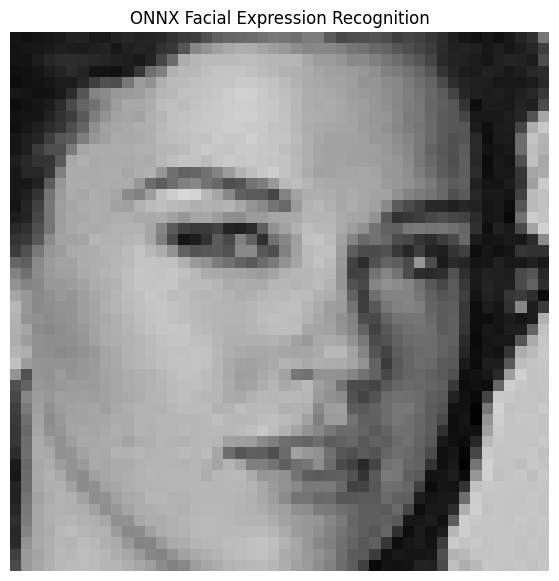

No face detected in this image.


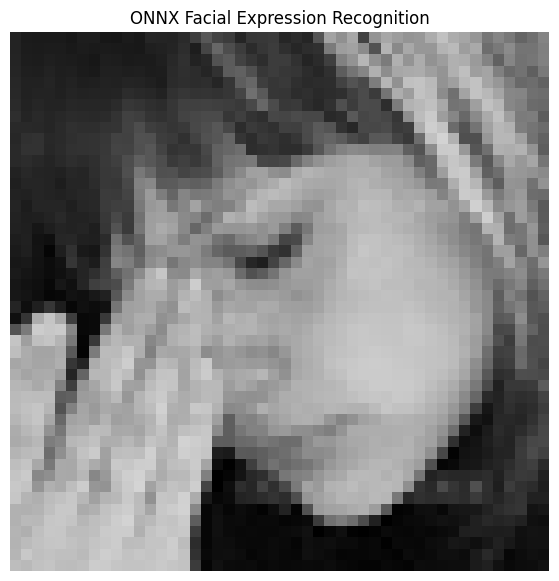

No face detected in this image.


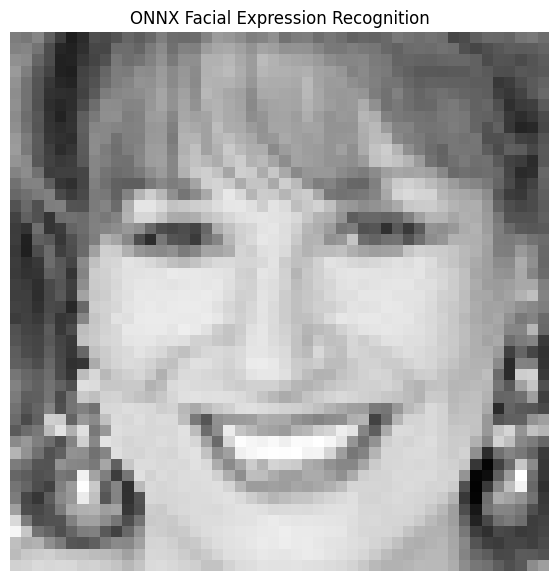

No face detected in this image.


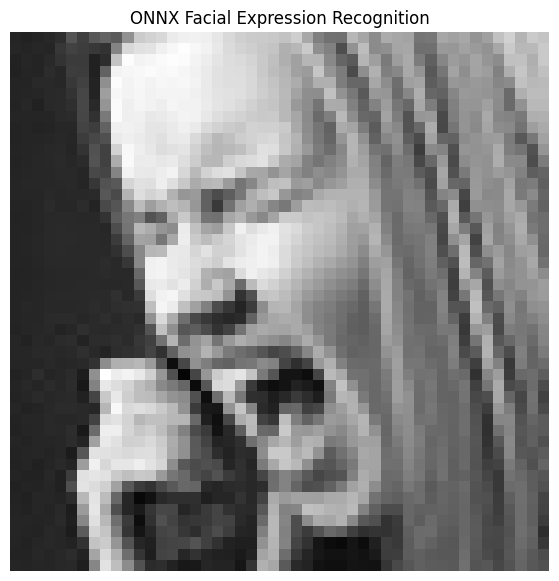

No face detected in this image.

Step 25 Completed!


In [40]:

# ==========================================
# Step 25 — ONNX Model Deployment
# Facial Expression Recognition
# ==========================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import onnxruntime as ort

from PIL import Image
from torchvision import transforms
from google.colab import files

# ------------------------------------------
# 1. Settings
# ------------------------------------------

ONNX_MODEL_PATH = (
    "/content/drive/MyDrive/FER2013_Models/"
    "resnet18_fer2013.onnx"
)

class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

# ------------------------------------------
# 2. Load ONNX Model
# ------------------------------------------

if not os.path.exists(ONNX_MODEL_PATH):
    raise FileNotFoundError(
        f"ONNX model not found: {ONNX_MODEL_PATH}"
    )

session = ort.InferenceSession(
    ONNX_MODEL_PATH,
    providers=["CPUExecutionProvider"]
)

input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

print("ONNX model loaded successfully!")
print("Provider:", session.get_providers())

# ------------------------------------------
# 3. Image Preprocessing
# ------------------------------------------

deployment_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------
# 4. Face Detection + ONNX Prediction
# ------------------------------------------

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

def predict_emotion(image_rgb):

    gray = cv2.cvtColor(
        image_rgb,
        cv2.COLOR_RGB2GRAY
    )

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40)
    )

    result_image = image_rgb.copy()
    results = []

    for (x, y, w, h) in faces:

        face = image_rgb[y:y+h, x:x+w]
        face_pil = Image.fromarray(face)

        input_tensor = deployment_transform(
            face_pil
        ).unsqueeze(0)

        # Convert PyTorch tensor to NumPy
        input_array = input_tensor.numpy().astype(
            np.float32
        )

        # ONNX Runtime inference
        outputs = session.run(
            [output_name],
            {input_name: input_array}
        )[0]

        # Softmax
        logits = outputs[0]
        exp_values = np.exp(
            logits - np.max(logits)
        )
        probabilities = exp_values / exp_values.sum()

        predicted = int(np.argmax(probabilities))
        confidence_value = float(
            probabilities[predicted] * 100
        )

        emotion = class_names[predicted]

        results.append({
            "emotion": emotion,
            "confidence": confidence_value
        })

        cv2.rectangle(
            result_image,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result_image,
            f"{emotion}: {confidence_value:.1f}%",
            (x, max(y-10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    return result_image, results


# ------------------------------------------
# 5. Upload Image
# ------------------------------------------

print("\nUpload an image to test the ONNX model:")

uploaded = files.upload()

for filename, image_bytes in uploaded.items():

    image_array = np.frombuffer(
        image_bytes,
        dtype=np.uint8
    )

    image_bgr = cv2.imdecode(
        image_array,
        cv2.IMREAD_COLOR
    )

    if image_bgr is None:
        print("Unable to read image:", filename)
        continue

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    result_image, predictions = predict_emotion(
        image_rgb
    )

    plt.figure(figsize=(9, 7))
    plt.imshow(result_image)
    plt.axis("off")
    plt.title("ONNX Facial Expression Recognition")
    plt.show()

    if predictions:
        for i, prediction in enumerate(
            predictions, start=1
        ):
            print(
                f"Face {i}: "
                f"{prediction['emotion']} | "
                f"Confidence: "
                f"{prediction['confidence']:.2f}%"
            )
    else:
        print("No face detected in this image.")

print("\nStep 25 Completed!")


Upload FER2013 images:


Saving PrivateTest_13726475.jpg to PrivateTest_13726475 (3).jpg
Saving PrivateTest_10702106.jpg to PrivateTest_10702106 (3).jpg
Saving PrivateTest_12052491.jpg to PrivateTest_12052491 (3).jpg
Saving PrivateTest_14740105.jpg to PrivateTest_14740105 (3).jpg


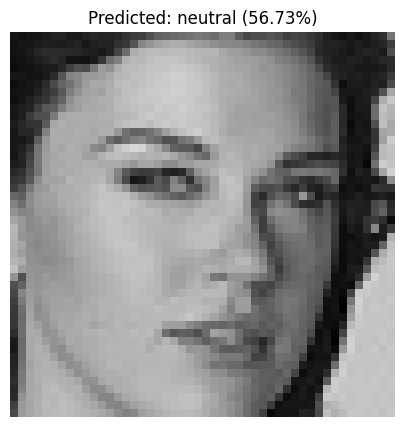

Image: PrivateTest_13726475 (3).jpg
Predicted Emotion: neutral
Confidence: 56.73%
----------------------------------------


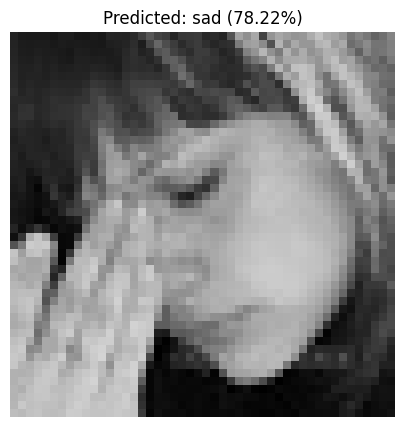

Image: PrivateTest_10702106 (3).jpg
Predicted Emotion: sad
Confidence: 78.22%
----------------------------------------


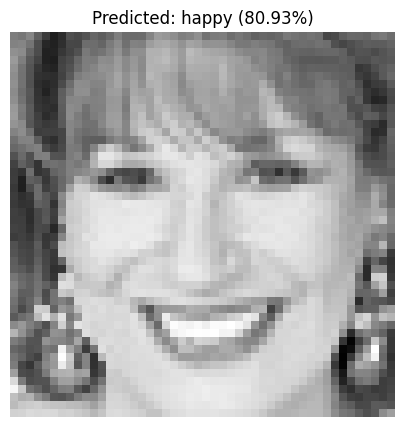

Image: PrivateTest_12052491 (3).jpg
Predicted Emotion: happy
Confidence: 80.93%
----------------------------------------


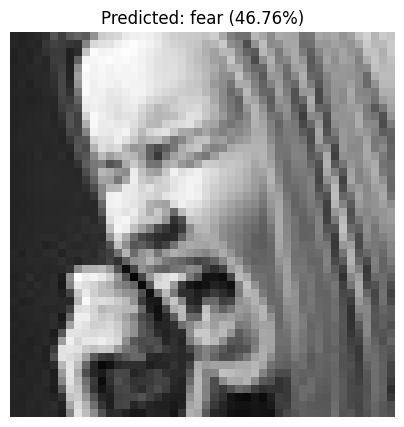

Image: PrivateTest_14740105 (3).jpg
Predicted Emotion: fear
Confidence: 46.76%
----------------------------------------
Step 25 Completed Successfully!


In [42]:


# ==========================================
# Step 25 — Fix for FER2013 Images (ONNX)
# ==========================================

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import io

print("Upload FER2013 images:")
uploaded = files.upload()

for filename, image_bytes in uploaded.items():

    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("RGB")

    # Same preprocessing as training
    input_tensor = deployment_transform(
        image
    ).unsqueeze(0)

    input_array = input_tensor.numpy().astype(
        np.float32
    )

    # ONNX prediction
    outputs = session.run(
        [output_name],
        {input_name: input_array}
    )[0]

    # Softmax
    logits = outputs[0]
    exp_values = np.exp(logits - np.max(logits))
    probabilities = exp_values / exp_values.sum()

    predicted = int(np.argmax(probabilities))
    confidence_value = float(
        probabilities[predicted] * 100
    )

    emotion = class_names[predicted]

    # Display
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Predicted: {emotion} "
        f"({confidence_value:.2f}%)"
    )
    plt.show()

    print(f"Image: {filename}")
    print(f"Predicted Emotion: {emotion}")
    print(f"Confidence: {confidence_value:.2f}%")
    print("-" * 40)

print("Step 25 Completed Successfully!")



In [43]:

!pip -q install gradio


## 11 . Live Webcam Emotion Detection

We create an interactive webcam interface for real-time facial emotion prediction.

**This section includes:**
- Load the trained model for live predictions.
- Capture frames from the webcam and prepare them for the model.
- Predict the emotion for each processed frame.
- Display the live prediction through an interactive Gradio interface.

<div dir="rtl">

## 11. التعرّف المباشر على المشاعر باستخدام الكاميرا

ننشئ واجهة تفاعلية تستخدم كاميرا الويب للتنبؤ بمشاعر الوجه في الوقت الفعلي.

**تشمل هذه المرحلة:**
- تحميل النموذج المدرّب لإجراء التوقعات المباشرة.
- التقاط إطارات من الكاميرا وتجهيزها للنموذج.
- التنبؤ بالشعور لكل إطار تتم معالجته.
- عرض التوقع المباشر من خلال واجهة Gradio التفاعلية.

</div>

In [ ]:

# ==========================================
# Step 26 — Live Webcam Detection
# ONNX Runtime + Haar Cascade + Gradio
# ==========================================

import os
import cv2
import numpy as np
import gradio as gr
import onnxruntime as ort

from PIL import Image
from torchvision import transforms

# ------------------------------------------
# 1. Settings
# ------------------------------------------

ONNX_MODEL_PATH = (
    "/content/drive/MyDrive/FER2013_Models/"
    "resnet18_fer2013.onnx"
)

class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

# ------------------------------------------
# 2. Load ONNX Model
# ------------------------------------------

if not os.path.exists(ONNX_MODEL_PATH):
    raise FileNotFoundError(
        f"ONNX model not found: {ONNX_MODEL_PATH}"
    )

live_session = ort.InferenceSession(
    ONNX_MODEL_PATH,
    providers=["CPUExecutionProvider"]
)

input_name = live_session.get_inputs()[0].name
output_name = live_session.get_outputs()[0].name

print("ONNX model loaded successfully!")
print("Provider:", live_session.get_providers())

# ------------------------------------------
# 3. Preprocessing
# ------------------------------------------

live_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------
# 4. Face Detector
# ------------------------------------------

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

if face_detector.empty():
    raise RuntimeError(
        "Face detector could not be loaded."
    )

# ------------------------------------------
# 5. Live Prediction Function
# ------------------------------------------

def detect_live_emotion(frame):

    if frame is None:
        return None

    frame = np.asarray(frame, dtype=np.uint8)

    # Gradio supplies RGB frames
    gray = cv2.cvtColor(
        frame,
        cv2.COLOR_RGB2GRAY
    )

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40)
    )

    output_frame = frame.copy()

    for (x, y, w, h) in faces:

        face_rgb = frame[y:y+h, x:x+w]

        if face_rgb.size == 0:
            continue

        face_pil = Image.fromarray(face_rgb)

        # Preprocess input
        input_tensor = live_transform(
            face_pil
        ).unsqueeze(0)

        input_array = input_tensor.numpy().astype(
            np.float32
        )

        # ONNX Runtime prediction
        outputs = live_session.run(
            [output_name],
            {input_name: input_array}
        )[0]

        # Softmax
        logits = outputs[0]
        exp_values = np.exp(
            logits - np.max(logits)
        )
        probabilities = exp_values / exp_values.sum()

        predicted = int(np.argmax(probabilities))
        score = float(probabilities[predicted] * 100)

        emotion = class_names[predicted]

        # Face bounding box
        cv2.rectangle(
            output_frame,
            (x, y),
            (x+w, y+h),
            (0, 255, 0),
            2
        )

        # Emotion label
        label = f"{emotion}: {score:.1f}%"

        cv2.putText(
            output_frame,
            label,
            (x, max(y-10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    return output_frame


# ------------------------------------------
# 6. Gradio Live Webcam Interface
# ------------------------------------------

with gr.Blocks(
    title="Live Facial Expression Recognition"
) as demo:

    gr.Markdown(
        "# Live Facial Expression Recognition"
    )

    gr.Markdown(
        "Real-time facial expression detection using "
        "ResNet18 Full Fine-Tuning, ONNX Runtime, "
        "and Haar Cascade."
    )

    with gr.Row():

        webcam_input = gr.Image(
            sources=["webcam"],
            streaming=True,
            type="numpy",
            label="Live Webcam"
        )

        prediction_output = gr.Image(
            type="numpy",
            label="Emotion Detection Result"
        )

    webcam_input.stream(
        fn=detect_live_emotion,
        inputs=webcam_input,
        outputs=prediction_output,
        stream_every=0.2,
        concurrency_limit=1
    )

# ------------------------------------------
# 7. Launch Application
# ------------------------------------------

demo.launch(
    share=True,
    debug=True
)


ONNX model loaded successfully!
Provider: ['CPUExecutionProvider']
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://a2992da6e3c2df71a4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


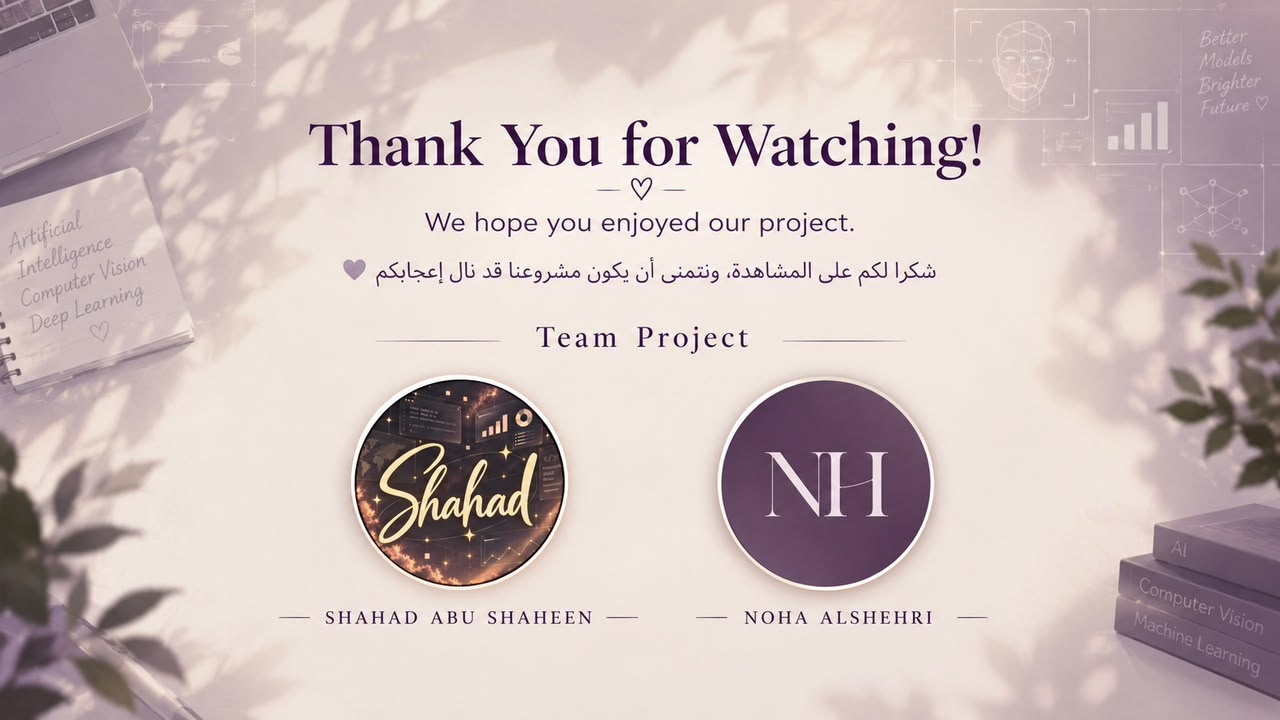